# Tugas PySpark — Big Data & Machine Learning
## Prediksi Tarif Taksi New York City (*NYC Taxi Fare Prediction*)

| | |
|---|---|
| **Mata kuliah** | Big Data — Modul 6 (PySpark) |
| **Anggota kelompok** | _Nama 1 (NIM)_ , _Nama 2 (NIM)_ |
| **Dataset** | Kaggle *New York City Taxi Fare Prediction* — `train.csv`, 55.423.856 baris (±5,3 GB CSV) |
| **Tools** | Apache Spark / PySpark (Spark SQL + MLlib), Pandas & Matplotlib hanya untuk visualisasi hasil agregasi |

**Tujuan:** memprediksi `fare_amount` (tarif taksi dalam USD, termasuk tol, belum termasuk tip) dari waktu
penjemputan, koordinat penjemputan/pengantaran, dan jumlah penumpang. Ini adalah masalah **regresi**.

**Struktur notebook** (mengikuti poin penilaian tugas):

0. Setup lingkungan Spark
1. Memuat dan menyiapkan data — *10 poin*
2. Eksplorasi data (EDA) — *15 poin*
3. Transformasi data / *preprocessing* — *15 poin*
4. Pemodelan dengan PySpark MLlib — *25 poin*
5. Evaluasi model — *15 poin*
6. *Hyperparameter tuning* — *10 poin*
7. Kesimpulan (laporan lengkap ada di `laporan/Laporan_Tugas_PySpark.md`)

> **Prinsip kerja big data di notebook ini:** semua pembersihan, agregasi, dan pelatihan model dikerjakan oleh
> Spark secara terdistribusi. Data baru dibawa ke Pandas **setelah** diringkas (hasil agregasi berukuran kecil)
> atau berupa sampel kecil khusus untuk grafik — tidak pernah seluruh 55 juta baris.

## 0. Setup Lingkungan

In [1]:
import os, json, math, time, platform
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from cycler import cycler

import pyspark
from pyspark.sql import SparkSession, Column, functions as F, types as T
from pyspark.storagelevel import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler, OneHotEncoder
from pyspark.ml.regression import (LinearRegression, DecisionTreeRegressor,
                                   RandomForestRegressor, GBTRegressor)
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.stat import Correlation

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
# ---------------- Konfigurasi ----------------
# DATA_PATH boleh berupa file train.csv dari Kaggle ATAU folder berisi file parquet (mirror Hugging Face).
DATA_PATH   = os.environ.get("NYC_TAXI_DATA", "../data/raw")
WORK_DIR    = os.environ.get("NYC_TAXI_WORK", "../data/work")   # parquet hasil olahan (tidak di-commit)
FIG_DIR     = "../figures"
RESULTS_DIR = "../results"
MODEL_DIR   = "../models"
for d in (WORK_DIR, FIG_DIR, RESULTS_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
# Ukuran data untuk tiap tahap pemodelan (lihat alasan di Bagian 4.1)
MODEL_TRAIN_ROWS = int(os.environ.get("MODEL_TRAIN_ROWS", 2_000_000))   # perbandingan 4 algoritma
TUNING_ROWS      = int(os.environ.get("TUNING_ROWS", 300_000))          # 3-fold cross-validation
FINAL_TRAIN_ROWS = int(os.environ.get("FINAL_TRAIN_ROWS", 8_000_000))   # model final hasil tuning

In [3]:
spark = (SparkSession.builder
         .appName("NYC-Taxi-Fare-PySpark")
         .master(os.environ.get("SPARK_MASTER", "local[*]"))
         .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "10g"))
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .config("spark.ui.showConsoleProgress", "false")
         # GBT membuat ribuan shuffle kecil; GC berkala membuat ContextCleaner segera menghapus file shuffle lama
         .config("spark.cleaner.periodicGC.interval", "1min")
         .config("spark.local.dir", os.environ.get("SPARK_LOCAL_DIR", "/tmp"))
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir(f"{WORK_DIR}/checkpoints")  # memutus lineage panjang GBT

sc = spark.sparkContext
print("Python       :", platform.python_version())
print("PySpark      :", pyspark.__version__)
print("Master       :", sc.master, "| default parallelism =", sc.defaultParallelism)
print("Driver memory:", spark.conf.get("spark.driver.memory"))

Python       : 3.13.18
PySpark      : 4.3.0
Master       : local[*] | default parallelism = 4
Driver memory: 10g


In [4]:
# Utilitas: pencatat waktu eksekusi & gaya grafik
TIMINGS = {}

@contextmanager
def timer(name):
    t0 = time.perf_counter()
    yield
    TIMINGS[name] = round(time.perf_counter() - t0, 1)
    print(f"[waktu] {name}: {TIMINGS[name]:,.1f} detik")

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
DIV_CMAP = LinearSegmentedColormap.from_list("div_rb", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b52f2f"])
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": cycler(color=PALETTE), "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))
    plt.show()

## 1. Memuat dan Menyiapkan Data (10 poin)

Dataset asli dari Kaggle (`new-york-city-taxi-fare-prediction/train.csv`) memiliki 8 kolom:

| Kolom | Tipe | Keterangan |
|---|---|---|
| `key` | string | ID unik (timestamp + nomor urut) |
| `fare_amount` | double | **target** — tarif dalam USD |
| `pickup_datetime` | string | waktu penjemputan, format `YYYY-MM-DD HH:MM:SS UTC` |
| `pickup_longitude`, `pickup_latitude` | double | koordinat penjemputan |
| `dropoff_longitude`, `dropoff_latitude` | double | koordinat pengantaran |
| `passenger_count` | int | jumlah penumpang |

Fungsi `load_raw` di bawah bisa membaca **CSV asli Kaggle** (dengan skema eksplisit agar Spark tidak perlu
melakukan *schema inference* yang mahal — membaca 5,3 GB dua kali) maupun **versi Parquet** (mirror Hugging Face
`shahbajsingh/nyc-taxi-fare-prediction-train`, isi identik dengan `train.csv`, 12 file ≈ 3,8 GB).

In [5]:
RAW_SCHEMA = T.StructType([
    T.StructField("key", T.StringType()),
    T.StructField("fare_amount", T.DoubleType()),
    T.StructField("pickup_datetime", T.StringType()),
    T.StructField("pickup_longitude", T.DoubleType()),
    T.StructField("pickup_latitude", T.DoubleType()),
    T.StructField("dropoff_longitude", T.DoubleType()),
    T.StructField("dropoff_latitude", T.DoubleType()),
    T.StructField("passenger_count", T.IntegerType()),
])

def load_raw(path):
    """Membaca train.csv (Kaggle) atau folder/file parquet."""
    if path.lower().endswith((".csv", ".csv.gz", ".zip")) or (os.path.isdir(path) and
            any(f.endswith(".csv") for f in os.listdir(path))):
        return spark.read.csv(path, header=True, schema=RAW_SCHEMA, mode="DROPMALFORMED")
    return spark.read.parquet(path)

def path_size_gb(path):
    if os.path.isfile(path):
        return os.path.getsize(path) / 1024**3
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1024**3

with timer("load_raw + count"):
    raw = load_raw(DATA_PATH)
    n_raw = raw.count()

print(f"Sumber data      : {os.path.abspath(DATA_PATH)}")
print(f"Ukuran di disk   : {path_size_gb(DATA_PATH):.2f} GB")
print(f"Jumlah baris     : {n_raw:,}")
print(f"Jumlah kolom     : {len(raw.columns)}")
print(f"Partisi Spark    : {raw.rdd.getNumPartitions()}")
raw.printSchema()

[waktu] load_raw + count: 6.3 detik
Sumber data      : /home/user/Big-Data/data/raw
Ukuran di disk   : 3.52 GB
Jumlah baris     : 55,423,856
Jumlah kolom     : 8
Partisi Spark    : 30
root
 |-- key: string (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- pickup_datetime: string (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- passenger_count: long (nullable = true)



In [6]:
raw.show(5, truncate=False)

+-----------------------------+-----------+-----------------------+------------------+------------------+------------------+----------------+---------------+
|key                          |fare_amount|pickup_datetime        |pickup_longitude  |pickup_latitude   |dropoff_longitude |dropoff_latitude|passenger_count|
+-----------------------------+-----------+-----------------------+------------------+------------------+------------------+----------------+---------------+
|2014-11-10 18:26:00.000000216|6.0        |2014-11-10 18:26:00 UTC|-74.001272        |40.72754          |-74.004107        |40.716987       |1              |
|2014-12-08 13:48:27.0000001  |7.0        |2014-12-08 13:48:27 UTC|-73.95193         |40.77767          |-73.962438        |40.763094       |1              |
|2015-01-16 15:21:39.0000002  |35.83      |2015-01-16 15:21:39 UTC|-73.98004150390625|40.752487182617195|-73.87189483642578|40.7742576599121|1              |
|2009-10-28 00:36:13.0000001  |12.9       |2009-10-2

### 1.1 Penyiapan tipe data

* `pickup_datetime` masih berupa **string** → dikonversi ke `timestamp` (akhiran ` UTC` dibuang).
* `passenger_count` dipastikan bertipe integer.
* `key` hanya berupa ID (timestamp + nomor urut), tidak informatif untuk model → dibuang.

**Zona waktu.** Walaupun berlabel `UTC`, perlu dicek apakah jam di data ini benar UTC atau sebenarnya jam
lokal New York — fitur jam (`hour`) bergantung pada hal ini. Sel berikut menghitung jumlah perjalanan per jam
dengan dua tafsiran tersebut.

Hasilnya disimpan sebagai **Parquet** (format kolumnar terkompresi). Untuk sumber CSV ini sangat mempercepat
semua tahap berikutnya karena Spark tidak perlu mem-*parse* teks 5,3 GB berulang kali, dan hanya membaca
kolom yang dibutuhkan (*column pruning*).

In [7]:
prepared = (raw
    .withColumn("pickup_datetime",
                F.to_timestamp(F.regexp_replace("pickup_datetime", r"\s*UTC$", ""), "yyyy-MM-dd HH:mm:ss"))
    .withColumn("passenger_count", F.col("passenger_count").cast("int"))
    .select("fare_amount", "pickup_datetime",
            "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
            "passenger_count"))

PREPARED_PATH = f"{WORK_DIR}/prepared.parquet"
with timer("tulis prepared.parquet"):
    prepared.write.mode("overwrite").parquet(PREPARED_PATH)

df = spark.read.parquet(PREPARED_PATH)
print(f"prepared.parquet : {path_size_gb(PREPARED_PATH):.2f} GB, {df.rdd.getNumPartitions()} partisi")
df.printSchema()
df.show(5)

[waktu] tulis prepared.parquet: 51.7 detik
prepared.parquet : 2.08 GB, 27 partisi
root
 |-- fare_amount: double (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- passenger_count: integer (nullable = true)



+-----------+-------------------+----------------+---------------+-----------------+----------------+---------------+
|fare_amount|    pickup_datetime|pickup_longitude|pickup_latitude|dropoff_longitude|dropoff_latitude|passenger_count|
+-----------+-------------------+----------------+---------------+-----------------+----------------+---------------+
|       14.5|2014-03-13 00:34:00|      -73.997578|      40.713997|       -73.939492|       40.700895|              1|
|       14.5|2010-05-14 15:16:17|      -73.961868|      40.779451|       -73.997145|       40.766983|              1|
|        8.5|2010-05-18 20:48:50|      -73.947849|      40.776067|       -73.975294|       40.752346|              1|
|       49.8|2012-07-15 08:08:56|      -73.979032|        40.7396|       -73.783346|       40.643817|              2|
|       17.0|2014-10-03 11:40:00|      -73.981777|      40.775205|       -73.990102|        40.74089|              4|
+-----------+-------------------+----------------+------

In [8]:
# Cek zona waktu: jam tersepi & tersibuk bila jam dibaca apa adanya vs bila dianggap UTC lalu dikonversi ke NYC
hour_check = (df.select(F.hour("pickup_datetime").alias("jam_apa_adanya"),
                        F.hour(F.from_utc_timestamp("pickup_datetime", "America/New_York")).alias("jam_jika_UTC"))
                .agg(*[F.count(F.when(F.col(c) == h, 1)).alias(f"{c}_{h}")
                       for c in ("jam_apa_adanya", "jam_jika_UTC") for h in range(24)])
                .first().asDict())
for c in ("jam_apa_adanya", "jam_jika_UTC"):
    s = pd.Series({h: hour_check[f"{c}_{h}"] for h in range(24)})
    print(f"{c:<15}: tersepi jam {s.idxmin():02d}.00 ({s.min():,}), tersibuk jam {s.idxmax():02d}.00 ({s.max():,})")

jam_apa_adanya : tersepi jam 05.00 (543,068), tersibuk jam 19.00 (3,465,001)
jam_jika_UTC   : tersepi jam 00.00 (604,954), tersibuk jam 15.00 (3,391,960)


**Hasil:** bila jam dibaca apa adanya, perjalanan paling sepi terjadi pukul 05.00 (543.068 perjalanan) dan paling ramai pukul 19.00 (3.465.001 perjalanan). Ini pola khas kota: dini hari sepi, puncak saat jam pulang kerja. Bila jam dianggap UTC lalu dikonversi ke waktu New York, jam tersepi bergeser ke 00.00 dan tersibuk ke 15.00, yang tidak masuk akal untuk taksi NYC.

**Kesimpulan:** label `UTC` pada data ini menyesatkan. Jamnya sudah jam lokal NYC, sehingga timestamp dipakai apa adanya tanpa konversi zona waktu.

## 2. Eksplorasi Data (EDA) (15 poin)

### 2.1 Statistik deskriptif
`summary()` dihitung Spark pada **seluruh 55 juta baris** (persentil memakai algoritma aproksimasi
Greenwald-Khanna yang scalable).

In [9]:
num_cols = ["fare_amount", "pickup_longitude", "pickup_latitude",
            "dropoff_longitude", "dropoff_latitude", "passenger_count"]
with timer("summary statistik"):
    summary_pd = (df.select(num_cols)
                  .summary("count", "mean", "stddev", "min", "1%", "25%", "50%", "75%", "99%", "max")
                  .toPandas().set_index("summary").astype(float))
summary_pd

[waktu] summary statistik: 50.9 detik


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
summary,,,,,,
count,"55,423,856.0000","55,423,856.0000","55,423,856.0000","55,423,480.0000","55,423,480.0000","55,423,856.0000"
mean,11.3450,-72.5097,39.9198,-72.5112,39.9207,1.6854
stddev,20.7108,12.8489,9.6424,12.7822,9.6333,1.3277
min,-300.0000,"-3,442.0596","-3,492.2638","-3,442.0246","-3,547.8867",0.0000
1%,3.3000,-74.0143,0.0000,-74.0153,0.0000,1.0000
25%,6.0000,-73.9921,40.7349,-73.9914,40.7340,1.0000
50%,8.5000,-73.9818,40.7527,-73.9802,40.7532,1.0000
75%,12.5000,-73.9671,40.7671,-73.9637,40.7681,2.0000
99%,53.0000,0.0000,40.8069,0.0000,40.8309,6.0000


In [10]:
time_range = df.agg(F.min("pickup_datetime").alias("awal"), F.max("pickup_datetime").alias("akhir")).first()
print("Rentang waktu data:", time_range["awal"], "s.d.", time_range["akhir"])

Rentang waktu data: 2009-01-01 00:00:27 s.d. 2015-06-30 23:59:54


### 2.2 Nilai kosong (*missing values*)

In [11]:
missing = df.select([F.sum(F.col(c).isNull().cast("long")).alias(c) for c in df.columns]).toPandas().T
missing.columns = ["jumlah_null"]
missing["persen"] = missing["jumlah_null"] / n_raw * 100
missing

,jumlah_null,persen
fare_amount,0,0.0000
pickup_datetime,0,0.0000
pickup_longitude,0,0.0000
pickup_latitude,0,0.0000
dropoff_longitude,376,0.0007
dropoff_latitude,376,0.0007
passenger_count,0,0.0000


### 2.3 Audit kualitas data (anomali)

Statistik di atas sudah memperlihatkan nilai-nilai yang mustahil (tarif negatif, koordinat bernilai ribuan
derajat, penumpang 208 orang, dsb.). Semua aturan berikut dihitung dalam **satu kali scan** data.
Batas wilayah NYC yang dipakai: longitude −74,27 s.d. −72,98 dan latitude 40,50 s.d. 41,72
(kotak yang mencakup lima *borough* + tiga bandara, sama dengan cakupan data uji Kaggle).

In [12]:
BBOX = dict(lon_min=-74.27, lon_max=-72.98, lat_min=40.50, lat_max=41.72)

def in_bbox(prefix):
    return (F.col(f"{prefix}_longitude").between(BBOX["lon_min"], BBOX["lon_max"]) &
            F.col(f"{prefix}_latitude").between(BBOX["lat_min"], BBOX["lat_max"]))

def haversine_km(lat1, lon1, lat2, lon2):
    """Jarak great-circle (km). Argumen boleh nama kolom (str) atau konstanta (float)."""
    def rad(x):
        return F.radians(F.col(x)) if isinstance(x, str) else F.lit(math.radians(x))
    lat1, lon1, lat2, lon2 = map(rad, (lat1, lon1, lat2, lon2))
    a = (F.pow(F.sin((lat2 - lat1) / 2), 2) +
         F.cos(lat1) * F.cos(lat2) * F.pow(F.sin((lon2 - lon1) / 2), 2))
    return 2 * 6371.0 * F.asin(F.sqrt(a))

any_null = None
for c in df.columns:
    any_null = F.col(c).isNull() if any_null is None else (any_null | F.col(c).isNull())

anomaly_rules = {
    "ada nilai null": any_null,
    "fare_amount <= 0": F.col("fare_amount") <= 0,
    "0 < fare_amount < 2,5 (di bawah tarif awal)": (F.col("fare_amount") > 0) & (F.col("fare_amount") < 2.5),
    "fare_amount > 250": F.col("fare_amount") > 250,
    "passenger_count = 0": F.col("passenger_count") == 0,
    "passenger_count > 6": F.col("passenger_count") > 6,
    "koordinat bernilai 0": ((F.col("pickup_longitude") == 0) | (F.col("pickup_latitude") == 0) |
                             (F.col("dropoff_longitude") == 0) | (F.col("dropoff_latitude") == 0)),
    "pickup di luar area NYC": ~in_bbox("pickup"),
    "dropoff di luar area NYC": ~in_bbox("dropoff"),
    "pickup == dropoff (jarak 0)": ((F.col("pickup_longitude") == F.col("dropoff_longitude")) &
                                    (F.col("pickup_latitude") == F.col("dropoff_latitude"))),
}
with timer("audit anomali"):
    anomaly_counts = df.agg(*[F.sum(F.when(cond, 1).otherwise(0)).alias(name)
                              for name, cond in anomaly_rules.items()]).first().asDict()
anomaly_pd = pd.DataFrame({"jumlah_baris": anomaly_counts})
anomaly_pd["persen"] = anomaly_pd["jumlah_baris"] / n_raw * 100
anomaly_pd

[waktu] audit anomali: 4.1 detik


,jumlah_baris,persen
ada nilai null,376,0.0007
fare_amount <= 0,3834,0.0069
"0 < fare_amount < 2,5 (di bawah tarif awal)",913,0.0016
fare_amount > 250,706,0.0013
passenger_count = 0,195416,0.3526
passenger_count > 6,116,0.0002
koordinat bernilai 0,1104490,1.9928
pickup di luar area NYC,1118248,2.0176
dropoff di luar area NYC,1115983,2.0135
pickup == dropoff (jarak 0),1581276,2.8531


**Temuan kualitas data (dari 55.423.856 baris):**

* 376 baris (0,0007%) tidak memiliki koordinat tujuan.
* 3.834 baris bertarif ≤ 0 (hingga −300 USD) dan 706 baris bertarif > 250 USD (maksimum 93.963 USD), hampir pasti salah input.
* 195.416 baris (0,35%) dengan `passenger_count = 0` dan 116 baris dengan lebih dari 6 penumpang (hingga 208).
* Masalah terbesar ada di koordinat: ±1,1 juta baris (≈2%) berkoordinat 0 (titik 0°, 0° di Teluk Guinea, Samudra Atlantik) atau berada di luar wilayah NYC.
* 1,58 juta baris (2,85%) memiliki koordinat jemput dan antar yang persis sama (jarak 0).

Kategori-kategori ini saling tumpang tindih; jumlah bersih yang dibuang dihitung berurutan di Bagian 3.1.

Untuk eksplorasi visual berikutnya dipakai **subset valid sementara** (`eda`) — baris dengan tarif
2,5–250 USD, penumpang 1–6, dan koordinat di dalam area NYC — supaya pola tidak tertutup *outlier*.
Aturan pembersihan resmi diterapkan dan didokumentasikan di Bagian 3.

In [13]:
eda = (df.dropna()
         .filter(F.col("fare_amount").between(2.5, 250) & F.col("passenger_count").between(1, 6) &
                 in_bbox("pickup") & in_bbox("dropoff"))
         .withColumn("distance_km", haversine_km("pickup_latitude", "pickup_longitude",
                                                 "dropoff_latitude", "dropoff_longitude"))
         .withColumn("year", F.year("pickup_datetime"))
         .withColumn("hour", F.hour("pickup_datetime"))
         .withColumn("dow", F.dayofweek("pickup_datetime")))

### 2.4 Distribusi target `fare_amount`

[waktu] distribusi fare: 13.6 detik
Persentil fare (1/5/25/50/75/95/99%): [3.3, 4.1, 6.0, 8.5, 12.5, 30.1, 53.0]


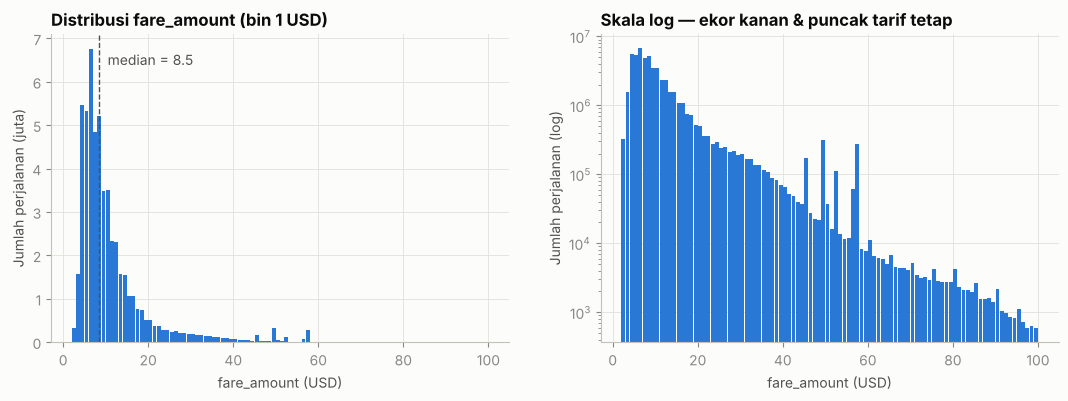

In [14]:
with timer("distribusi fare"):
    fare_q = eda.approxQuantile("fare_amount", [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99], 0.001)
    fare_hist = (eda.filter(F.col("fare_amount") < 100)
                    .groupBy(F.floor("fare_amount").alias("bin")).count().orderBy("bin").toPandas())
print("Persentil fare (1/5/25/50/75/95/99%):", [round(v, 2) for v in fare_q])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(fare_hist["bin"] + 0.5, fare_hist["count"] / 1e6, width=0.9, color=PALETTE[0])
axes[0].set_title("Distribusi fare_amount (bin 1 USD)")
axes[0].set_xlabel("fare_amount (USD)"); axes[0].set_ylabel("Jumlah perjalanan (juta)")
axes[0].axvline(fare_q[3], color=INK2, lw=1, ls="--")
axes[0].annotate(f"median = {fare_q[3]:.1f}", (fare_q[3], axes[0].get_ylim()[1] * 0.9),
                 xytext=(6, 0), textcoords="offset points", color=INK2)
axes[1].bar(fare_hist["bin"] + 0.5, fare_hist["count"], width=0.9, color=PALETTE[0])
axes[1].set_yscale("log")
axes[1].set_title("Skala log — ekor kanan & puncak tarif tetap")
axes[1].set_xlabel("fare_amount (USD)"); axes[1].set_ylabel("Jumlah perjalanan (log)")
savefig(fig, "01_distribusi_fare")

### 2.5 Pola temporal

In [15]:
with timer("agregasi temporal"):
    by_year = (eda.groupBy("year").agg(F.count("*").alias("trips"), F.avg("fare_amount").alias("avg_fare"),
                                       F.avg("distance_km").alias("avg_km"))
                  .orderBy("year").toPandas())
    by_month = (eda.groupBy(F.date_trunc("month", "pickup_datetime").alias("month"))
                   .agg(F.avg("fare_amount").alias("avg_fare"),
                        F.percentile_approx(F.col("fare_amount") / F.greatest(F.col("distance_km"), F.lit(0.5)),
                                            0.5).alias("median_fare_per_km"),
                        F.count("*").alias("trips"))
                   .orderBy("month").toPandas())
    by_hour = (eda.groupBy("hour").agg(F.count("*").alias("trips"), F.avg("fare_amount").alias("avg_fare"),
                                       F.avg("distance_km").alias("avg_km"))
                  .orderBy("hour").toPandas())
    dow_hour = (eda.groupBy("dow").pivot("hour", list(range(24))).agg(F.avg("fare_amount"))
                   .orderBy("dow").toPandas().set_index("dow"))
by_year

[waktu] agregasi temporal: 47.2 detik


,year,trips,avg_fare,avg_km
0,2009,8431912,10.0523,3.2209
1,2010,8167357,10.1575,3.2372
2,2011,8489538,10.4387,3.2988
3,2012,8629740,11.1548,3.3679
4,2013,8478884,12.5496,3.3927
5,2014,8071658,12.8781,3.4140
6,2015,3779155,12.9497,3.3978


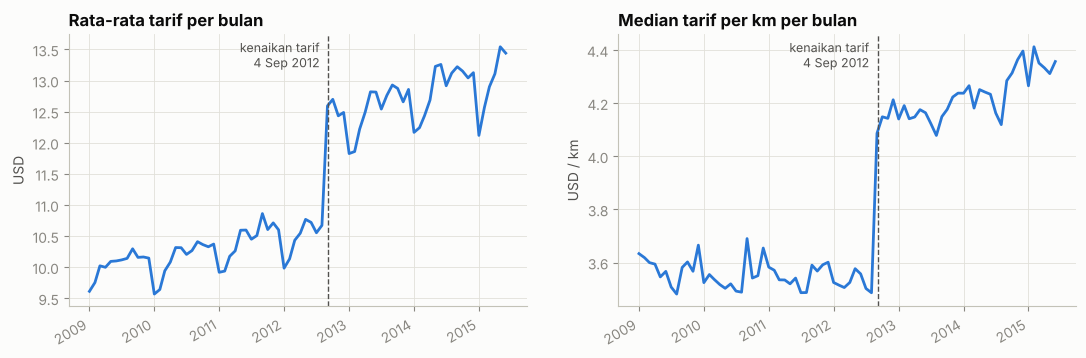

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(by_month["month"], by_month["avg_fare"], color=PALETTE[0])
axes[0].set_title("Rata-rata tarif per bulan")
axes[0].set_ylabel("USD")
axes[1].plot(by_month["month"], by_month["median_fare_per_km"], color=PALETTE[0])
axes[1].set_title("Median tarif per km per bulan")
axes[1].set_ylabel("USD / km")
for ax in axes:
    ax.axvline(pd.Timestamp("2012-09-04"), color=INK2, lw=1, ls="--")
    ax.annotate("kenaikan tarif\n4 Sep 2012", (pd.Timestamp("2012-09-04"), ax.get_ylim()[1]),
                xytext=(-6, -4), textcoords="offset points", ha="right", va="top", color=INK2, fontsize=9)
fig.autofmt_xdate()
savefig(fig, "02_tren_bulanan")

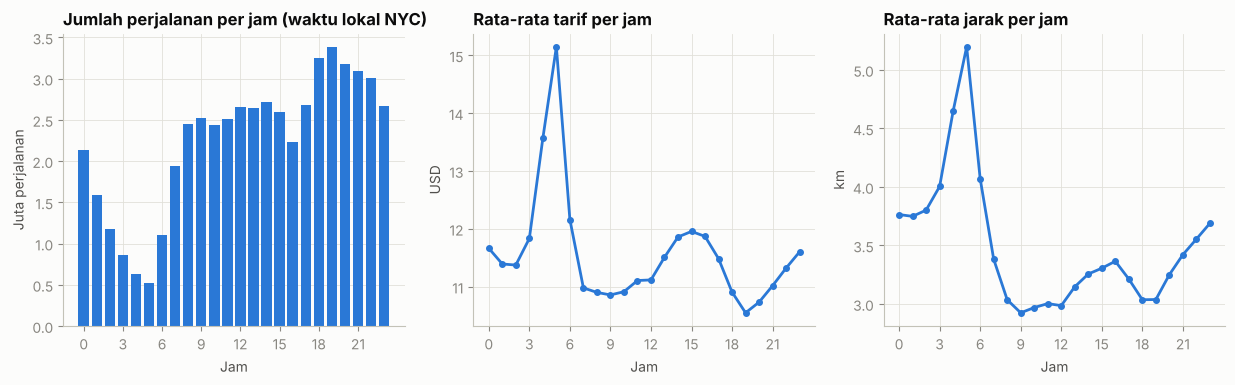

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(by_hour["hour"], by_hour["trips"] / 1e6, width=0.8, color=PALETTE[0])
axes[0].set_title("Jumlah perjalanan per jam (waktu lokal NYC)")
axes[0].set_xlabel("Jam"); axes[0].set_ylabel("Juta perjalanan")
axes[1].plot(by_hour["hour"], by_hour["avg_fare"], marker="o", ms=4, color=PALETTE[0])
axes[1].set_title("Rata-rata tarif per jam"); axes[1].set_xlabel("Jam"); axes[1].set_ylabel("USD")
axes[2].plot(by_hour["hour"], by_hour["avg_km"], marker="o", ms=4, color=PALETTE[0])
axes[2].set_title("Rata-rata jarak per jam"); axes[2].set_xlabel("Jam"); axes[2].set_ylabel("km")
for ax in axes:
    ax.set_xticks(range(0, 24, 3))
savefig(fig, "03_pola_jam")

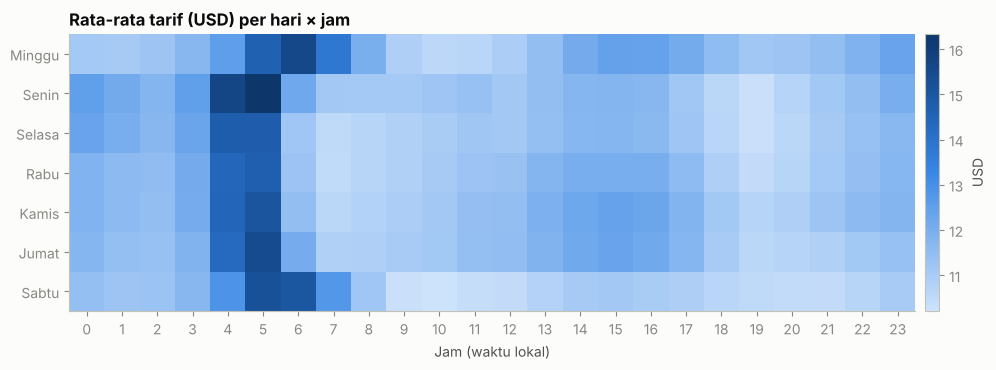

In [18]:
DOW_LABEL = {1: "Minggu", 2: "Senin", 3: "Selasa", 4: "Rabu", 5: "Kamis", 6: "Jumat", 7: "Sabtu"}
fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(dow_hour.values, aspect="auto", cmap=SEQ_CMAP)
ax.set_yticks(range(7)); ax.set_yticklabels([DOW_LABEL[d] for d in dow_hour.index])
ax.set_xticks(range(24)); ax.set_xlabel("Jam (waktu lokal)")
ax.set_title("Rata-rata tarif (USD) per hari × jam"); ax.grid(False)
fig.colorbar(im, ax=ax, label="USD", pad=0.01)
savefig(fig, "04_heatmap_hari_jam")

### 2.6 Jumlah penumpang

In [19]:
by_pass = (df.groupBy("passenger_count").agg(F.count("*").alias("trips"), F.avg("fare_amount").alias("avg_fare"))
             .orderBy("passenger_count").toPandas())
by_pass["persen"] = by_pass["trips"] / n_raw * 100
by_pass

,passenger_count,trips,avg_fare,persen
0,0,195416,9.0153,0.3526
1,1,38337524,11.2164,69.1715
2,2,8175243,11.8384,14.7504
3,3,2432712,11.5406,4.3893
4,4,1178852,11.7661,2.1270
5,5,3929346,11.2084,7.0896
6,6,1174647,12.1262,2.1194
7,7,15,31.7887,0.0000
8,8,9,29.9811,0.0000
9,9,23,36.9930,0.0000


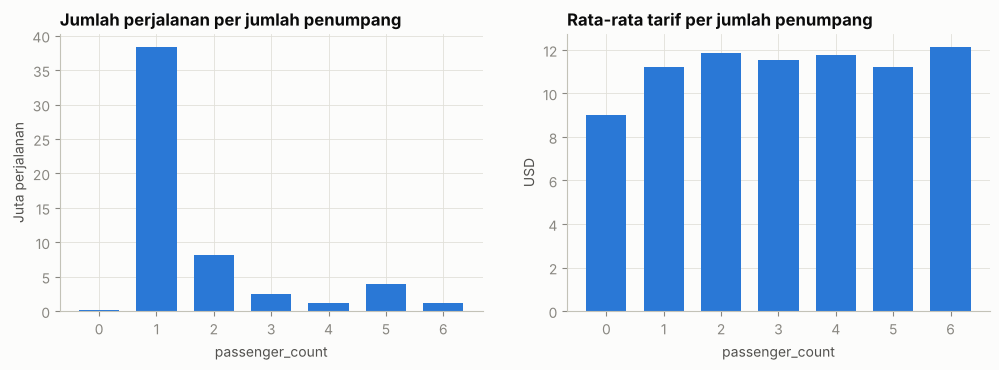

In [20]:
pv = by_pass[by_pass["passenger_count"].between(0, 6)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(pv["passenger_count"], pv["trips"] / 1e6, width=0.7, color=PALETTE[0])
axes[0].set_title("Jumlah perjalanan per jumlah penumpang"); axes[0].set_ylabel("Juta perjalanan")
axes[1].bar(pv["passenger_count"], pv["avg_fare"], width=0.7, color=PALETTE[0])
axes[1].set_title("Rata-rata tarif per jumlah penumpang"); axes[1].set_ylabel("USD")
for ax in axes:
    ax.set_xlabel("passenger_count"); ax.set_xticks(range(0, 7))
savefig(fig, "05_penumpang")

### 2.7 Hubungan jarak dan tarif

Jarak *haversine* (garis lurus di permukaan bumi) dihitung dari koordinat. Statistik per *bin* jarak
dihitung Spark pada seluruh subset valid; *scatter*/hexbin memakai sampel acak ±300 ribu baris.

[waktu] agregasi jarak: 22.3 detik
Korelasi Pearson jarak–tarif (sampel): 0.833


Perjalanan dengan jarak < 0,05 km: 803,825


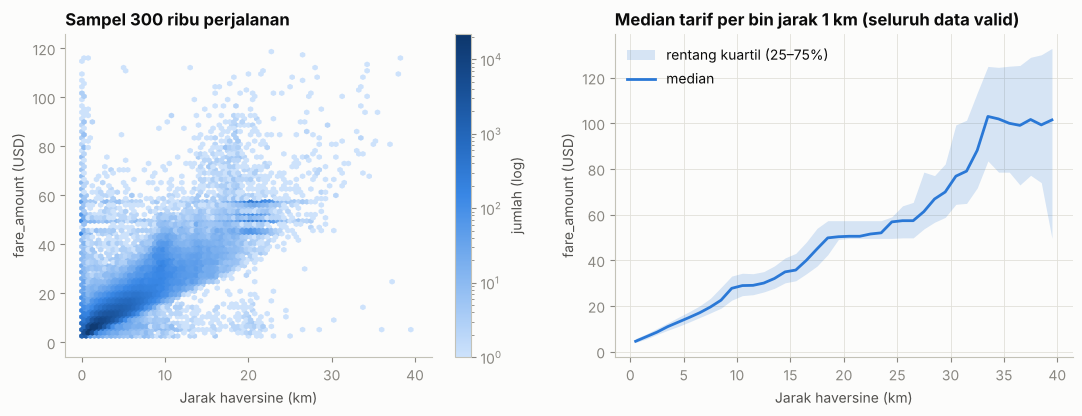

In [21]:
with timer("agregasi jarak"):
    by_dist = (eda.filter(F.col("distance_km") < 40)
                  .groupBy(F.floor("distance_km").alias("km"))
                  .agg(F.count("*").alias("trips"),
                       F.percentile_approx("fare_amount", [0.25, 0.5, 0.75]).alias("q"))
                  .orderBy("km").toPandas())
    eda_sample = (eda.sample(fraction=300_000 / 50_000_000, seed=SEED)
                     .select("fare_amount", "distance_km", "year").toPandas())
by_dist[["q25", "q50", "q75"]] = pd.DataFrame(by_dist["q"].tolist(), index=by_dist.index)
print("Korelasi Pearson jarak–tarif (sampel):",
      round(eda_sample[["fare_amount", "distance_km"]].corr().iloc[0, 1], 3))
print("Perjalanan dengan jarak < 0,05 km:", f"{eda.filter(F.col('distance_km') < 0.05).count():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hb = axes[0].hexbin(eda_sample["distance_km"], eda_sample["fare_amount"], gridsize=80, bins="log",
                    cmap=SEQ_CMAP, mincnt=1, extent=(0, 40, 0, 120))
axes[0].set_title("Sampel 300 ribu perjalanan"); axes[0].set_xlabel("Jarak haversine (km)")
axes[0].set_ylabel("fare_amount (USD)"); axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label="jumlah (log)")
axes[1].fill_between(by_dist["km"] + 0.5, by_dist["q25"], by_dist["q75"], color=PALETTE[0], alpha=0.18,
                     lw=0, label="rentang kuartil (25–75%)")
axes[1].plot(by_dist["km"] + 0.5, by_dist["q50"], color=PALETTE[0], label="median")
axes[1].set_title("Median tarif per bin jarak 1 km (seluruh data valid)")
axes[1].set_xlabel("Jarak haversine (km)"); axes[1].set_ylabel("fare_amount (USD)")
axes[1].legend(loc="upper left")
savefig(fig, "06_jarak_vs_tarif")

### 2.8 Sebaran geografis penjemputan & pengantaran

Peta kepadatan dibuat dengan *binning* 2D di Spark (grid ±0,001°) — hanya hasil hitungan per sel yang dibawa
ke driver, jadi tetap ringan walaupun datanya puluhan juta titik.

[waktu] peta kepadatan: 10.3 detik


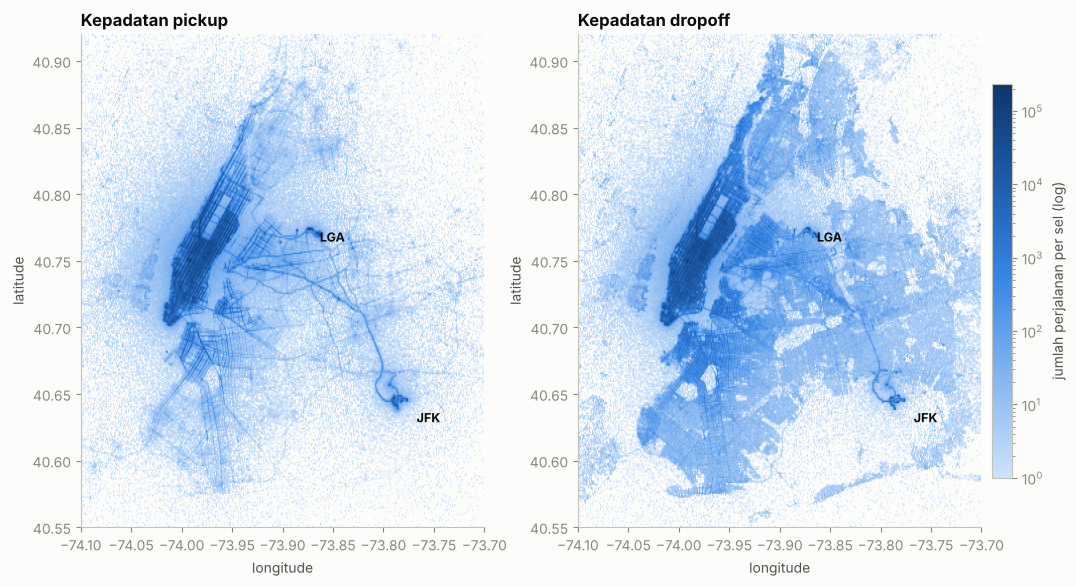

In [22]:
VIEW = dict(lon_min=-74.10, lon_max=-73.70, lat_min=40.55, lat_max=40.92)
STEP = 0.001
nx = int(round((VIEW["lon_max"] - VIEW["lon_min"]) / STEP))
ny = int(round((VIEW["lat_max"] - VIEW["lat_min"]) / STEP))

def density_grid(prefix):
    lon, lat = F.col(f"{prefix}_longitude"), F.col(f"{prefix}_latitude")
    g = (eda.filter(lon.between(VIEW["lon_min"], VIEW["lon_max"] - 1e-9) &
                    lat.between(VIEW["lat_min"], VIEW["lat_max"] - 1e-9))
            .groupBy(F.floor((lon - VIEW["lon_min"]) / STEP).cast("int").alias("ix"),
                     F.floor((lat - VIEW["lat_min"]) / STEP).cast("int").alias("iy"))
            .count().toPandas())
    grid = np.zeros((ny, nx))
    grid[g["iy"].clip(0, ny - 1), g["ix"].clip(0, nx - 1)] = g["count"]
    return grid

with timer("peta kepadatan"):
    grids = {p: density_grid(p) for p in ("pickup", "dropoff")}

AIRPORTS = {"JFK": (40.6413, -73.7781), "LGA": (40.7769, -73.8740), "EWR": (40.6895, -74.1745)}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (p, grid) in zip(axes, grids.items()):
    masked = np.ma.masked_where(grid == 0, grid)
    im = ax.imshow(masked, origin="lower", cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=grid.max()),
                   extent=(VIEW["lon_min"], VIEW["lon_max"], VIEW["lat_min"], VIEW["lat_max"]), aspect=1.32)
    for name, (la, lo) in AIRPORTS.items():
        if VIEW["lon_min"] < lo < VIEW["lon_max"]:
            ax.annotate(name, (lo, la), xytext=(8, -12), textcoords="offset points", color=INK, fontsize=9,
                        fontweight="bold")
    ax.set_title(f"Kepadatan {p}"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(False)
fig.colorbar(im, ax=axes, label="jumlah perjalanan per sel (log)", shrink=0.8, pad=0.01)
savefig(fig, "07_peta_kepadatan")

### 2.9 Perjalanan bandara
Bandara adalah lokasi dengan tarif khusus (misalnya tarif flat JFK ↔ Manhattan). Perjalanan dikelompokkan
berdasarkan apakah titik jemput/antar berada dalam radius 2 km dari JFK, LaGuardia (LGA), atau Newark (EWR).

In [23]:
def near(prefix, ap, radius_km=2.0):
    la, lo = AIRPORTS[ap]
    return haversine_km(f"{prefix}_latitude", f"{prefix}_longitude", la, lo) < radius_km

trip_type = (F.when(near("pickup", "JFK") | near("dropoff", "JFK"), "JFK")
              .when(near("pickup", "LGA") | near("dropoff", "LGA"), "LGA")
              .when(near("pickup", "EWR") | near("dropoff", "EWR"), "EWR")
              .otherwise("Non-bandara"))
with timer("agregasi bandara"):
    airport_pd = (eda.withColumn("trip_type", trip_type)
                     .groupBy("trip_type")
                     .agg(F.count("*").alias("trips"), F.avg("fare_amount").alias("avg_fare"),
                          F.percentile_approx("fare_amount", 0.5).alias("median_fare"),
                          F.avg("distance_km").alias("avg_km"))
                     .orderBy(F.desc("trips")).toPandas())
airport_pd["persen"] = airport_pd["trips"] / airport_pd["trips"].sum() * 100
airport_pd

[waktu] agregasi bandara: 18.0 detik


,trip_type,trips,avg_fare,median_fare,avg_km,persen
0,Non-bandara,51080266,9.8049,8.1000,2.7691,94.5087
1,LGA,1760890,30.6158,30.6700,9.5787,3.2580
2,JFK,1136171,45.9148,49.8000,17.9121,2.1021
3,EWR,70917,70.2560,70.6900,16.4289,0.1312


### 2.10 Ringkasan temuan EDA

1. **Target sangat menceng ke kanan.** Median 8,5 USD dan 75% perjalanan ≤ 12,5 USD, tetapi persentil 99% mencapai 53 USD. Ada puncak-puncak tajam di sekitar 45–58 USD: tarif flat bandara JFK (45 USD sebelum September 2012, 52 USD sesudahnya, ditambah tol/surcharge).
2. **Ada perubahan rezim tarif pada 4 September 2012.** Median tarif per km melonjak dari ±3,55 menjadi ±4,15 USD/km (≈ +17%) dalam satu bulan, dan rata-rata tarif tahunan naik dari 11,15 USD (2012) ke 12,55 USD (2013). Model perlu tahu tanggal perjalanan → fitur `year_frac` dan `after_fare_hike`.
3. **Pola jam.** Jumlah perjalanan paling sedikit pukul 05.00, tetapi justru pada jam itu tarif dan jarak rata-rata tertinggi (±15 USD, ±5 km): dini hari didominasi perjalanan jauh ke/dari bandara. Heatmap menunjukkan puncak ini terjadi pukul 04–05 pada hari kerja dan bergeser ke 05–07 pada akhir pekan.
4. **`passenger_count` hampir tidak berpengaruh** pada tarif (rata-rata 11,2–12,1 USD untuk 1–6 penumpang); 69% perjalanan hanya berisi 1 penumpang. Ini sesuai aturan tarif NYC yang tidak bergantung pada jumlah penumpang.
5. **Jarak adalah prediktor terkuat** (korelasi Pearson ±0,83 pada sampel) dengan hubungan hampir linear sampai ±20 km; di atas itu sebarannya melebar (tol, kemacetan, tarif flat). Ada 803.825 perjalanan dengan jarak < 50 m yang tetap bertarif — tarifnya tidak bisa dijelaskan dari lokasi.
6. **Geografi.** Penjemputan sangat terpusat di Manhattan, sedangkan pengantaran lebih menyebar ke Brooklyn dan Queens. Bandara terlihat jelas sebagai titik padat. Perjalanan bandara hanya ±5,5% data, tetapi rata-rata tarifnya 3–7 kali lipat (median JFK 49,80 USD, LGA 30,67 USD, EWR 70,69 USD vs 8,10 USD untuk non-bandara), sehingga fitur jarak ke tiap bandara akan sangat membantu.

## 3. Transformasi Data / Preprocessing (15 poin)

### 3.1 Pembersihan data

Aturan diterapkan berurutan; jumlah baris yang terbuang pada tiap aturan dihitung dalam satu scan.

| # | Aturan | Alasan |
|---|---|---|
| R1 | buang baris dengan nilai null | koordinat tujuan kosong tidak bisa dipakai |
| R2 | 2,5 ≤ `fare_amount` ≤ 250 | tarif awal (*flag drop*) minimal USD 2,50; tarif negatif/nol tidak valid; > 250 sangat langka (<0,01%) dan mayoritas salah input |
| R3 | 1 ≤ `passenger_count` ≤ 6 | kapasitas taksi kuning NYC maksimal 5–6 penumpang; 0 penumpang = salah input |
| R4 | pickup & dropoff di dalam area NYC | koordinat 0 atau di luar kota (laut, benua lain) adalah error GPS |
| R5 | 0,05 km ≤ jarak ≤ 100 km | jarak 0 → tarif tidak bisa dijelaskan oleh lokasi (pembatalan, GPS mati); > 100 km tidak masuk akal di dalam kotak NYC |
| R6 | hapus baris duplikat | duplikasi membuat bobot sampel tidak seimbang |

In [24]:
dist_col = haversine_km("pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude")
rules = [
    ("R1 null", ~any_null),
    ("R2 fare 2.5-250", F.col("fare_amount").between(2.5, 250)),
    ("R3 penumpang 1-6", F.col("passenger_count").between(1, 6)),
    ("R4 koordinat di NYC", in_bbox("pickup") & in_bbox("dropoff")),
    ("R5 jarak 0.05-100 km", dist_col.between(0.05, 100)),
]
# Hitung berapa baris yang PERTAMA kali gugur di tiap aturan (satu scan)
aggs, passed_so_far = [], F.lit(True)
for name, cond in rules:
    aggs.append(F.sum(F.when(passed_so_far & ~F.coalesce(cond, F.lit(False)), 1).otherwise(0)).alias(name))
    passed_so_far = passed_so_far & F.coalesce(cond, F.lit(False))
with timer("funnel pembersihan"):
    removed = df.agg(*aggs).first().asDict()

clean_filter = F.lit(True)
for _, cond in rules:
    clean_filter = clean_filter & F.coalesce(cond, F.lit(False))

# Sekaligus ditambahkan kolom `split` (80% train / 20% test, acak dengan seed) yang ditulis sebagai partisi
# folder, sehingga pembagian data tersimpan permanen & identik di setiap pembacaan (lihat 3.4).
with timer("filter + dropDuplicates + tulis clean.parquet"):
    CLEAN_PATH = f"{WORK_DIR}/clean.parquet"
    (df.filter(clean_filter).dropDuplicates()
       .withColumn("split", F.when(F.rand(seed=SEED) < 0.8, "train").otherwise("test"))
       .write.mode("overwrite").partitionBy("split").parquet(CLEAN_PATH))
    clean = spark.read.parquet(CLEAN_PATH)
    n_clean = clean.count()
print(f"clean.parquet : {path_size_gb(CLEAN_PATH):.2f} GB, {clean.rdd.getNumPartitions()} partisi")

n_after_rules = n_raw - sum(removed.values())
removed["R6 duplikat"] = n_after_rules - n_clean
funnel = pd.DataFrame({"baris_dibuang": removed})
funnel["persen_dari_awal"] = funnel["baris_dibuang"] / n_raw * 100
funnel.loc["TOTAL dibuang"] = [n_raw - n_clean, (n_raw - n_clean) / n_raw * 100]
funnel.loc["SISA (data bersih)"] = [n_clean, n_clean / n_raw * 100]
funnel

[waktu] funnel pembersihan: 4.5 detik


[waktu] filter + dropDuplicates + tulis clean.parquet: 49.4 detik
clean.parquet : 2.05 GB, 22 partisi


,baris_dibuang,persen_dari_awal
R1 null,376.0000,0.0007
R2 fare 2.5-250,"5,453.0000",0.0098
R3 penumpang 1-6,"195,108.0000",0.3520
R4 koordinat di NYC,"1,174,675.0000",2.1194
R5 jarak 0.05-100 km,"805,629.0000",1.4536
R6 duplikat,32.0000,0.0001
TOTAL dibuang,"2,181,273.0000",3.9356
SISA (data bersih),"53,242,583.0000",96.0644


Total **2.181.273 baris (3,94%) dibuang**, menyisakan **53.242.583 baris bersih (96,06%)**. Penyumbang terbesar adalah koordinat di luar NYC/bernilai 0 (1,17 juta baris) dan jarak < 50 m (0,81 juta baris); duplikat persis hanya 32 baris. Angka per aturan di sini lebih kecil daripada audit di Bagian 2.3 karena baris yang sudah gugur di aturan sebelumnya tidak dihitung lagi. Filter, deduplikasi (shuffle 53 juta baris), dan penulisan Parquet selesai dalam ±50 detik.

### 3.2 Rekayasa fitur (*feature engineering*)

Model hanya menerima angka, sementara informasi penting tersembunyi di timestamp dan pasangan koordinat.
Fitur yang dibangun (semua dengan fungsi bawaan Spark SQL → dieksekusi terdistribusi, tanpa UDF Python):

| Kelompok | Fitur | Intuisi |
|---|---|---|
| Waktu | `year`, `month`, `day_of_week`, `hour`, `year_frac` | inflasi/kenaikan tarif dari tahun ke tahun, pola mingguan & harian |
| Waktu (flag) | `is_weekend`, `is_night` (20.00–06.00), `is_peak` (16.00–20.00 hari kerja), `after_fare_hike` (≥ 4 Sep 2012) | surcharge malam USD 0,50, surcharge jam sibuk USD 1, kenaikan tarif resmi 2012 |
| Jarak | `distance_km` (haversine), `manhattan_km`, `delta_lon`, `delta_lat`, `bearing` | argometer menghitung jarak tempuh di jalan berpola grid |
| Lokasi | 4 koordinat mentah, jarak pickup/dropoff ke **JFK, LGA, EWR** dan ke **Midtown Manhattan**, `airport_trip` | tarif flat bandara, surcharge Newark, kepadatan lalu lintas di pusat kota |
| Lain | `passenger_count` | — |
| Interaksi (khusus regresi linear) | `dist_x_hike` = `distance_km × after_fare_hike` | tarif per km naik setelah Sep 2012 — model linear butuh interaksi eksplisit |

In [25]:
LANDMARKS = {**{k.lower(): v for k, v in AIRPORTS.items()}, "center": (40.7580, -73.9855)}  # Times Square

def add_features(sdf):
    ts = F.col("pickup_datetime")
    out = (sdf
        .withColumn("year", F.year(ts))
        .withColumn("month", F.month(ts))
        .withColumn("day_of_week", F.dayofweek(ts))            # 1 = Minggu ... 7 = Sabtu
        .withColumn("hour", F.hour(ts))
        .withColumn("year_frac", F.year(ts) + (F.dayofyear(ts) - 1) / 365.25)
        .withColumn("is_weekend", F.dayofweek(ts).isin(1, 7).cast("int"))
        .withColumn("is_night", ((F.hour(ts) >= 20) | (F.hour(ts) < 6)).cast("int"))
        .withColumn("is_peak", (F.hour(ts).between(16, 19) & ~F.dayofweek(ts).isin(1, 7)).cast("int"))
        .withColumn("after_fare_hike", (ts >= F.lit("2012-09-04 00:00:00").cast("timestamp")).cast("int"))
        .withColumn("delta_lon", F.col("dropoff_longitude") - F.col("pickup_longitude"))
        .withColumn("delta_lat", F.col("dropoff_latitude") - F.col("pickup_latitude"))
        .withColumn("distance_km", haversine_km("pickup_latitude", "pickup_longitude",
                                                "dropoff_latitude", "dropoff_longitude"))
        # 1° lat ≈ 111,0 km; 1° lon ≈ 84,2 km pada lintang 40,7°
        .withColumn("manhattan_km", F.abs(F.col("delta_lat")) * 111.0 + F.abs(F.col("delta_lon")) * 84.2)
        .withColumn("bearing", F.degrees(F.atan2(F.col("delta_lon") * 84.2, F.col("delta_lat") * 111.0)))
        .withColumn("dist_x_hike", F.col("distance_km") * F.col("after_fare_hike")))
    for name, (la, lo) in LANDMARKS.items():
        for p in ("pickup", "dropoff"):
            out = out.withColumn(f"{p}_dist_{name}", haversine_km(f"{p}_latitude", f"{p}_longitude", la, lo))
    near_airport = None
    for ap in ("jfk", "lga", "ewr"):
        c = (F.col(f"pickup_dist_{ap}") < 2) | (F.col(f"dropoff_dist_{ap}") < 2)
        near_airport = c if near_airport is None else (near_airport | c)
    return out.withColumn("airport_trip", near_airport.cast("int"))

TREE_FEATURES = [
    "passenger_count", "year", "month", "day_of_week", "hour", "year_frac",
    "is_weekend", "is_night", "is_peak", "after_fare_hike",
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
    "delta_lon", "delta_lat", "distance_km", "manhattan_km", "bearing",
    "pickup_dist_jfk", "dropoff_dist_jfk", "pickup_dist_lga", "dropoff_dist_lga",
    "pickup_dist_ewr", "dropoff_dist_ewr", "pickup_dist_center", "dropoff_dist_center", "airport_trip",
]

# Fitur TIDAK ditulis ulang ke disk: `add_features` hanya menambah ekspresi pada rencana eksekusi (lazy) dan
# dihitung ulang saat data dibaca. Menghitung ~20 ekspresi trigonometri jauh lebih murah daripada membaca
# ulang tabel fitur selebar 37 kolom (±7,7 GB) — dan menghemat ruang disk.
feats = add_features(clean)
print(f"{len(feats.columns) - 1} kolom setelah feature engineering (dari {len(clean.columns) - 1} kolom bersih)")
feats.select("fare_amount", "pickup_datetime", "hour", "day_of_week", "distance_km", "manhattan_km",
             "bearing", "pickup_dist_jfk", "dropoff_dist_center", "airport_trip").show(5)

31 kolom setelah feature engineering (dari 7 kolom bersih)
+-----------+-------------------+----+-----------+------------------+-------------------+-------------------+------------------+-------------------+------------+
|fare_amount|    pickup_datetime|hour|day_of_week|       distance_km|       manhattan_km|            bearing|   pickup_dist_jfk|dropoff_dist_center|airport_trip|
+-----------+-------------------+----+-----------+------------------+-------------------+-------------------+------------------+-------------------+------------+
|       24.0|2014-02-21 09:11:52|   9|          6|10.223269227627119| 13.203936800000166|  21.14982647368486| 22.32374635447926| 11.469906431092733|           0|
|        7.7|2011-05-15 10:37:38|  10|          1| 3.012466159074093|  4.118797800000223| 30.524063472042602|21.073173678641595| 2.2845103875857724|           0|
|      33.83|2014-11-09 11:58:00|  11|          1| 8.981916121569226| 10.682878000000379| 102.25121412261909|23.464090866743238|   

### 3.3 Korelasi fitur dengan target
Matriks korelasi Pearson dihitung dengan `pyspark.ml.stat.Correlation` atas **seluruh data bersih**: kolom
digabung menjadi satu vektor, lalu MLlib menghitung matriks kovarians dalam satu pass terdistribusi
(`treeAggregate`). Cara ini jauh lebih efisien daripada memanggil `F.corr` untuk 120 pasangan kolom satu per
satu.

[waktu] matriks korelasi: 62.1 detik


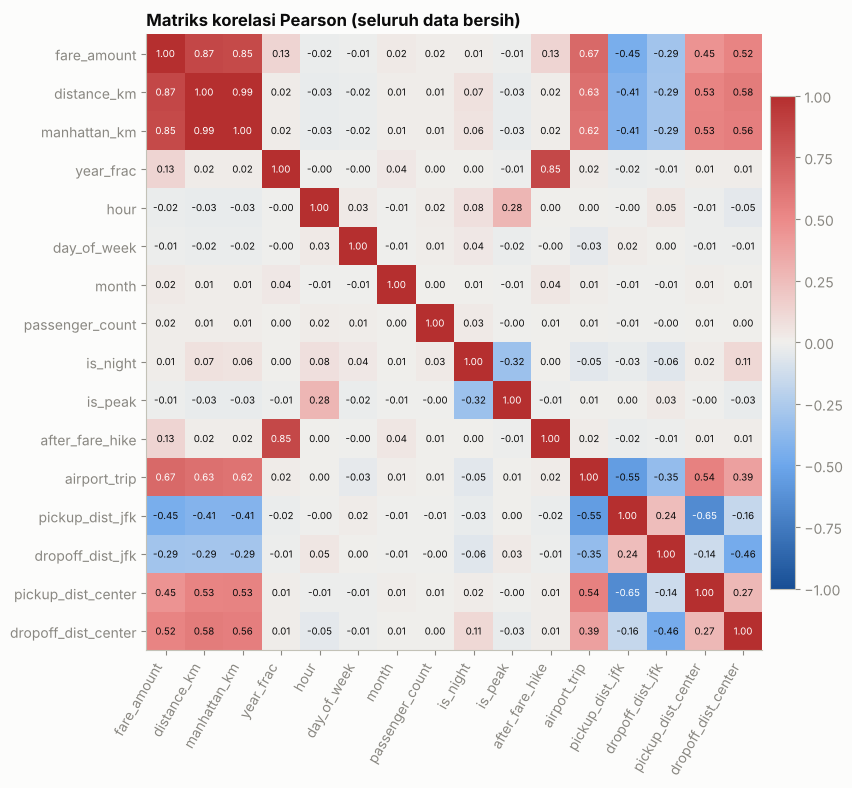

,korelasi_dg_fare
distance_km,0.8665
manhattan_km,0.8503
airport_trip,0.6720
dropoff_dist_center,0.5246
pickup_dist_center,0.4499
pickup_dist_jfk,-0.4462
dropoff_dist_jfk,-0.2892
after_fare_hike,0.1319
year_frac,0.1254
month,0.0247


In [26]:
CORR_COLS = ["fare_amount", "distance_km", "manhattan_km", "year_frac", "hour", "day_of_week", "month",
             "passenger_count", "is_night", "is_peak", "after_fare_hike", "airport_trip",
             "pickup_dist_jfk", "dropoff_dist_jfk", "pickup_dist_center", "dropoff_dist_center"]
with timer("matriks korelasi"):
    corr_vec = VectorAssembler(inputCols=CORR_COLS, outputCol="v").transform(feats.select(CORR_COLS))
    corr_arr = Correlation.corr(corr_vec, "v", "pearson").head()[0].toArray()
corr_mat = pd.DataFrame(corr_arr, index=CORR_COLS, columns=CORR_COLS)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_mat.values, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_COLS))); ax.set_xticklabels(CORR_COLS, rotation=60, ha="right")
ax.set_yticks(range(len(CORR_COLS))); ax.set_yticklabels(CORR_COLS)
for i in range(len(CORR_COLS)):
    for j in range(len(CORR_COLS)):
        v = corr_mat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="#ffffff" if abs(v) > 0.6 else INK)
ax.set_title("Matriks korelasi Pearson (seluruh data bersih)"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
savefig(fig, "08_korelasi")
corr_mat["fare_amount"].drop("fare_amount").sort_values(key=abs, ascending=False).to_frame("korelasi_dg_fare")

### 3.4 Pembagian data latih & uji
Data bersih dibagi **80% latih / 20% uji** secara acak (`F.rand(seed=42)`). Pembagian sudah ditulis sebagai
partisi folder `split=train` / `split=test` saat menyimpan `clean.parquet` (Bagian 3.1), sehingga:

* pembagiannya permanen dan identik setiap kali dibaca (berbeda dengan `randomSplit` yang harus mengurutkan
  ulang tiap partisi setiap kali data dibaca agar deterministik — mahal untuk 54 juta baris);
* Spark cukup membaca folder yang dibutuhkan (*partition pruning*).

Data uji (±10 juta baris) **tidak pernah disentuh** saat pelatihan maupun tuning — hanya untuk evaluasi akhir.

In [27]:
train = feats.filter(F.col("split") == "train").drop("split")
test = feats.filter(F.col("split") == "test").drop("split")
with timer("split + count"):
    n_train, n_test = train.count(), test.count()
print(f"Train: {n_train:,} baris | Test: {n_test:,} baris")

[waktu] split + count: 0.3 detik
Train: 42,592,531 baris | Test: 10,650,052 baris


### 3.5 Pipeline transformasi MLlib

* **Model berbasis pohon** (Decision Tree, Random Forest, GBT): cukup `VectorAssembler` — pohon tidak
  sensitif terhadap skala dan bisa memotong variabel waktu/lokasi secara non-linear.
* **Regresi linear**: `hour`, `day_of_week`, `month`, `year` diperlakukan sebagai kategori lewat
  `OneHotEncoder` (efek jam tidak linear), fitur numerik di-`StandardScaler`, dan ditambah fitur interaksi
  `dist_x_hike`.

Semua langkah dibungkus `Pipeline` sehingga transformasi yang sama persis dipakai saat training,
tuning (di dalam tiap fold CV), dan prediksi.

In [28]:
CAT_COLS = ["hour", "day_of_week", "month", "year"]
LR_NUM = [c for c in TREE_FEATURES if c not in CAT_COLS] + ["dist_x_hike"]

def tree_assembler():
    return VectorAssembler(inputCols=TREE_FEATURES, outputCol="features")

def lr_stages():
    ohe = OneHotEncoder(inputCols=CAT_COLS, outputCols=[f"{c}_ohe" for c in CAT_COLS], handleInvalid="keep")
    num_vec = VectorAssembler(inputCols=LR_NUM, outputCol="num_vec")
    scaler = StandardScaler(inputCol="num_vec", outputCol="num_scaled", withMean=True, withStd=True)
    final = VectorAssembler(inputCols=["num_scaled"] + [f"{c}_ohe" for c in CAT_COLS], outputCol="features")
    return [ohe, num_vec, scaler, final]

## 4. Pemodelan dengan PySpark MLlib (25 poin)

### 4.1 Strategi

Target `fare_amount` kontinu → algoritma **regresi**. Empat algoritma MLlib dibandingkan:

1. **Linear Regression** (dengan regularisasi *elastic-net* kecil) — baseline yang mudah ditafsirkan.
2. **Decision Tree Regressor** — menangkap hubungan non-linear & interaksi (mis. tarif flat bandara).
3. **Random Forest Regressor** — *bagging* banyak pohon → varians lebih rendah.
4. **Gradient-Boosted Trees (GBT) Regressor** — *boosting*, biasanya paling akurat untuk data tabular.

Sebagai pembanding paling sederhana juga dihitung **baseline rata-rata** (selalu menebak rata-rata tarif).

**Pengaturan skala data.** Notebook ini dijalankan pada Spark mode lokal (1 mesin, 4 core). ETL, EDA dan
evaluasi memakai seluruh data. Untuk pelatihan dipakai strategi bertingkat:

| Tahap | Data latih | Tujuan |
|---|---|---|
| Perbandingan 4 algoritma (Bagian 4–5) | sampel acak `MODEL_TRAIN_ROWS` dari data train | perbandingan adil, semua model di data yang sama |
| Cross-validation (Bagian 6) | sampel `TUNING_ROWS` | 3-fold × beberapa kombinasi parameter = puluhan model |
| Model final (Bagian 6) | sampel `FINAL_TRAIN_ROWS` | hyperparameter terbaik dilatih ulang dengan data jauh lebih besar |

Evaluasi **selalu** pada seluruh data uji (±10 juta baris). Pada klaster sungguhan, cukup ubah variabel
konfigurasi (atau `SPARK_MASTER`) untuk melatih pada 100% data — kodenya tidak berubah.

In [29]:
frac = min(1.0, MODEL_TRAIN_ROWS / n_train)
# Sampel kecil dipadatkan ke sedikit partisi: algoritma pohon MLlib menjalankan 1 job Spark per level pohon,
# sehingga puluhan partisi kecil hanya menambah overhead penjadwalan task.
N_PART = sc.defaultParallelism * 2
MODEL_COLS = ["fare_amount"] + TREE_FEATURES + ["dist_x_hike"]
train_s = (train.sample(fraction=frac, seed=SEED).select(MODEL_COLS)
                .repartition(N_PART).persist(StorageLevel.MEMORY_AND_DISK))
n_train_s = train_s.count()
print(f"Sampel latih untuk perbandingan model: {n_train_s:,} baris ({frac:.2%} dari data train)")

Sampel latih untuk perbandingan model: 1,998,131 baris (4.70% dari data train)


In [30]:
def regression_metrics(pred_df, label="fare_amount", pred="prediction"):
    """RMSE, MAE, R² dan MSE dalam SATU scan (RegressionEvaluator butuh satu scan per metrik)."""
    err = F.col(pred) - F.col(label)
    r = pred_df.agg(F.count("*").alias("n"), F.sum(err * err).alias("sse"), F.sum(F.abs(err)).alias("sae"),
                    F.avg(label).alias("ybar"), F.var_pop(label).alias("yvar")).first()
    mse = r["sse"] / r["n"]
    return {"RMSE": math.sqrt(mse), "MAE": r["sae"] / r["n"], "R2": 1 - mse / r["yvar"], "MSE": mse}

models = {
    "Linear Regression": Pipeline(stages=lr_stages() + [
        LinearRegression(featuresCol="features", labelCol="fare_amount", maxIter=100,
                         regParam=0.01, elasticNetParam=0.1)]),
    "Decision Tree": Pipeline(stages=[tree_assembler(),
        DecisionTreeRegressor(featuresCol="features", labelCol="fare_amount", maxDepth=10, maxBins=64,
                              seed=SEED)]),
    "Random Forest": Pipeline(stages=[tree_assembler(),
        RandomForestRegressor(featuresCol="features", labelCol="fare_amount", numTrees=40, maxDepth=10,
                              maxBins=64, subsamplingRate=0.8, featureSubsetStrategy="onethird", seed=SEED)]),
    "GBT": Pipeline(stages=[tree_assembler(),
        GBTRegressor(featuresCol="features", labelCol="fare_amount", maxIter=60, maxDepth=6,
                     stepSize=0.1, maxBins=64, subsamplingRate=0.8, seed=SEED)]),
}

fitted, train_time = {}, {}
for name, pipe in models.items():
    t0 = time.perf_counter()
    fitted[name] = pipe.fit(train_s)
    train_time[name] = time.perf_counter() - t0
    print(f"{name:<18} selesai dilatih dalam {train_time[name]:7.1f} detik")

Linear Regression  selesai dilatih dalam    13.2 detik


Decision Tree      selesai dilatih dalam    10.2 detik


Random Forest      selesai dilatih dalam   102.9 detik


GBT                selesai dilatih dalam   126.5 detik


### 4.2 Interpretasi model
**Koefisien regresi linear** (fitur numerik sudah distandardisasi, jadi besarnya koefisien sebanding) dan
**feature importance** dari model pohon.

In [31]:
lr_model = fitted["Linear Regression"].stages[-1]
coef = pd.Series(lr_model.coefficients.toArray()[:len(LR_NUM)], index=LR_NUM)
print(f"Intercept: {lr_model.intercept:.3f}")
coef.sort_values(key=abs, ascending=False).head(12).to_frame("koefisien (per 1 std)")

Intercept: 11.286


,koefisien (per 1 std)
distance_km,8.9048
pickup_dist_jfk,-3.2049
manhattan_km,-2.4250
pickup_longitude,-2.4145
dist_x_hike,1.7787
airport_trip,1.5662
dropoff_longitude,-1.5568
delta_lat,-1.1129
delta_lon,1.0408
pickup_dist_lga,-0.7750


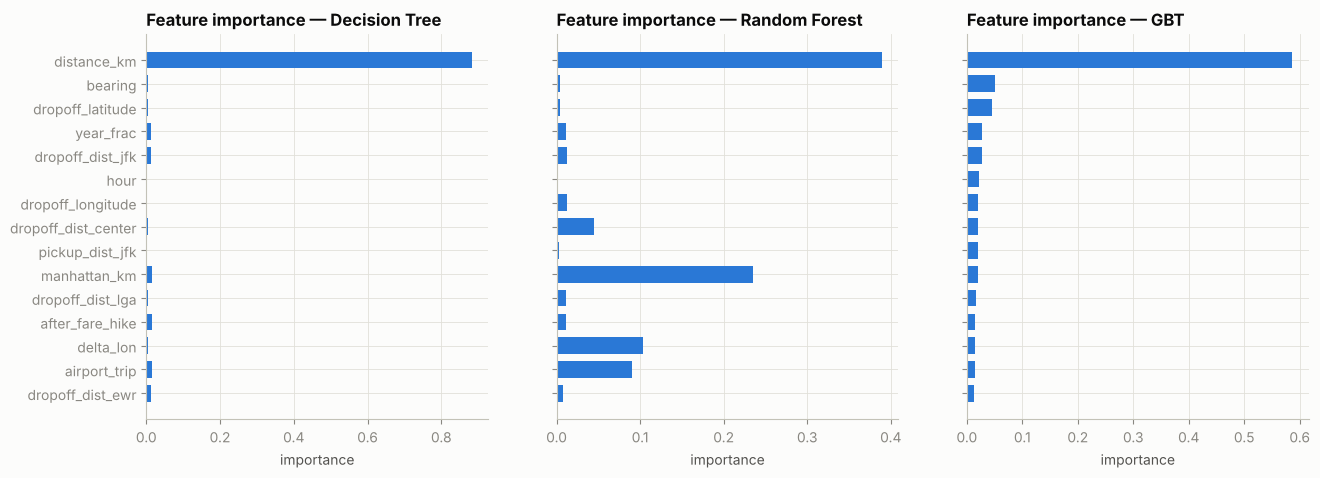

,Decision Tree,Random Forest,GBT
distance_km,0.8830,0.3897,0.5870
bearing,0.0054,0.0043,0.0504
dropoff_latitude,0.0043,0.0042,0.0462
year_frac,0.0137,0.0109,0.0277
dropoff_dist_jfk,0.0120,0.0119,0.0275
hour,0.0016,0.0010,0.0217
dropoff_longitude,0.0028,0.0129,0.0204
dropoff_dist_center,0.0037,0.0446,0.0200
pickup_dist_jfk,0.0013,0.0024,0.0198
manhattan_km,0.0143,0.2353,0.0196


In [32]:
imp = pd.DataFrame({name: fitted[name].stages[-1].featureImportances.toArray()
                    for name in ("Decision Tree", "Random Forest", "GBT")}, index=TREE_FEATURES)
top = imp.sort_values("GBT", ascending=True).tail(15)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, name in zip(axes, imp.columns):
    ax.barh(top.index, top[name], color=PALETTE[0], height=0.7)
    ax.set_title(f"Feature importance — {name}"); ax.set_xlabel("importance")
savefig(fig, "09_feature_importance")
imp.sort_values("GBT", ascending=False).head(10)

**Interpretasi:**

* Regresi linear memberi bobot terbesar pada `distance_km` (+8,9 USD per 1 simpangan baku jarak) dan `dist_x_hike` (+1,8), artinya tarif per km memang lebih mahal setelah September 2012. Koefisien negatif `pickup_dist_jfk` (−3,2) berarti makin dekat titik jemput ke JFK, makin mahal tarifnya.
* Ketiga model pohon sepakat bahwa **jarak** adalah fitur terpenting (39–88% importance). Random Forest membagi kepentingan ke fitur jarak lain yang saling berkorelasi (`manhattan_km`, `delta_lon`), sedangkan GBT, yang membangun pohon bertahap untuk memperbaiki residual, memanfaatkan lebih banyak fitur sekunder: arah perjalanan (`bearing`), lokasi tujuan, jarak ke JFK, dan waktu (`year_frac`, `hour`).
* Waktu latih pada ±2 juta baris: Linear Regression 13 detik, Decision Tree 10 detik, Random Forest 103 detik, GBT 127 detik.

## 5. Evaluasi Model (15 poin)

Metrik regresi yang dipakai:

* **RMSE** (*Root Mean Squared Error*) — metrik resmi kompetisi Kaggle ini; dalam satuan USD, menghukum
  kesalahan besar lebih berat.
* **MAE** (*Mean Absolute Error*) — rata-rata selisih absolut dalam USD, lebih tahan *outlier*.
* **R²** — proporsi variasi tarif yang dapat dijelaskan model (1 = sempurna, 0 = setara menebak rata-rata).

Model dievaluasi pada **seluruh data uji** dan juga pada data latihnya untuk melihat *overfitting*.

In [33]:
mean_fare = train_s.agg(F.avg("fare_amount")).first()[0]
rows = []
with timer("evaluasi test set"):
    base = regression_metrics(test.withColumn("prediction", F.lit(mean_fare)))
    rows.append({"model": "Baseline (rata-rata)", **{f"test_{k}": v for k, v in base.items()},
                 "train_RMSE": float("nan"), "waktu_latih_s": 0.0})
    for name, m in fitted.items():
        te = regression_metrics(m.transform(test))
        tr = regression_metrics(m.transform(train_s))
        rows.append({"model": name, **{f"test_{k}": v for k, v in te.items()},
                     "train_RMSE": tr["RMSE"], "waktu_latih_s": train_time[name]})
        print(f"{name:<18} test RMSE = {te['RMSE']:.4f} | MAE = {te['MAE']:.4f} | R2 = {te['R2']:.4f}")
results = pd.DataFrame(rows).set_index("model")
results[["test_RMSE", "test_MAE", "test_R2", "train_RMSE", "waktu_latih_s"]]

Linear Regression  test RMSE = 3.8136 | MAE = 1.9553 | R2 = 0.8358


Decision Tree      test RMSE = 3.4195 | MAE = 1.7586 | R2 = 0.8680


Random Forest      test RMSE = 3.3081 | MAE = 1.7316 | R2 = 0.8764


GBT                test RMSE = 3.1701 | MAE = 1.5728 | R2 = 0.8865
[waktu] evaluasi test set: 179.4 detik


,test_RMSE,test_MAE,test_R2,train_RMSE,waktu_latih_s
model,,,,,
Baseline (rata-rata),9.4111,5.9164,-0.0000,NaN,0.0000
Linear Regression,3.8136,1.9553,0.8358,3.8260,13.1972
Decision Tree,3.4195,1.7586,0.8680,3.2759,10.2490
Random Forest,3.3081,1.7316,0.8764,3.2257,102.9311
GBT,3.1701,1.5728,0.8865,3.0697,126.5032


In [34]:
# Verifikasi: fungsi metrik satu-scan memberi hasil yang sama dengan RegressionEvaluator bawaan MLlib
best_name = results.drop("Baseline (rata-rata)")["test_RMSE"].idxmin()
pred_best = fitted[best_name].transform(test).select("fare_amount", "prediction")
ev = RegressionEvaluator(labelCol="fare_amount", predictionCol="prediction", metricName="rmse")
print(f"Model terbaik: {best_name}")
print(f"RMSE (RegressionEvaluator): {ev.evaluate(pred_best):.4f}  vs  fungsi satu-scan: "
      f"{results.loc[best_name, 'test_RMSE']:.4f}")

Model terbaik: GBT


RMSE (RegressionEvaluator): 3.1701  vs  fungsi satu-scan: 3.1701


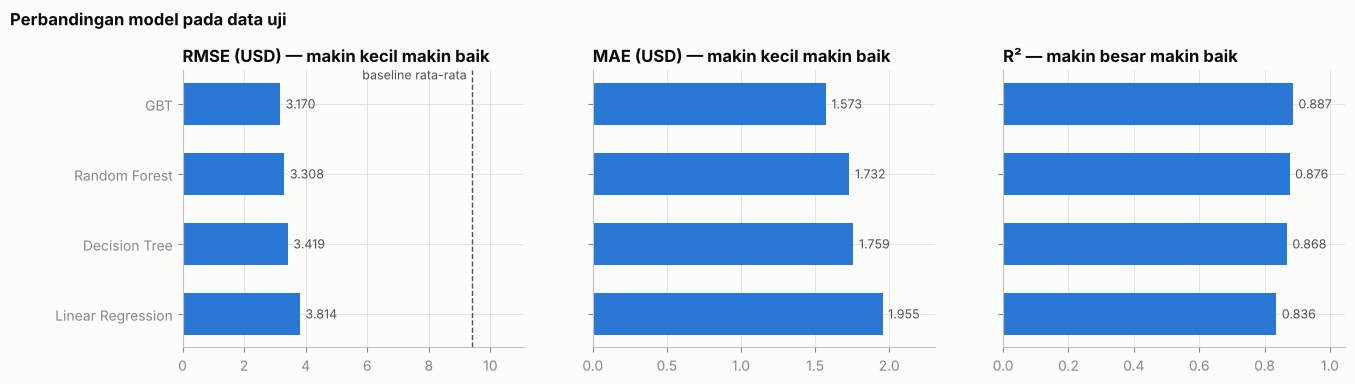

In [35]:
plot_df = results.drop("Baseline (rata-rata)").sort_values("test_RMSE")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, metric, label in zip(axes, ["test_RMSE", "test_MAE", "test_R2"],
                             ["RMSE (USD) — makin kecil makin baik", "MAE (USD) — makin kecil makin baik",
                              "R² — makin besar makin baik"]):
    ax.barh(plot_df.index[::-1], plot_df[metric][::-1], color=PALETTE[0], height=0.6)
    for i, v in enumerate(plot_df[metric][::-1]):
        ax.annotate(f"{v:.3f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center",
                    color=INK2, fontsize=9)
    ax.set_title(label); ax.margins(x=0.18)
axes[0].axvline(results.loc["Baseline (rata-rata)", "test_RMSE"], color=INK2, ls="--", lw=1)
axes[0].annotate("baseline rata-rata", (results.loc["Baseline (rata-rata)", "test_RMSE"], 3.35),
                 ha="right", xytext=(-4, 0), textcoords="offset points", color=INK2, fontsize=9)
fig.suptitle("Perbandingan model pada data uji", x=0.01, y=1.05, ha="left", fontweight="bold")
savefig(fig, "10_perbandingan_model")

**Hasil evaluasi pada 10.650.052 baris data uji:**

* Semua model jauh lebih baik daripada baseline rata-rata (RMSE 9,41 USD). **GBT terbaik** dengan RMSE 3,170 USD, MAE 1,573 USD, dan R² 0,887: rata-rata meleset ±1,6 USD dan menjelaskan 88,7% variasi tarif.
* Urutan RMSE: GBT (3,170) < Random Forest (3,308) < Decision Tree (3,420) < Linear Regression (3,814). Model pohon unggul karena struktur tarif yang non-linear (tarif flat bandara, surcharge berdasarkan jam, lonjakan tarif 2012).
* **Overfitting kecil**: selisih RMSE latih vs uji hanya 0,08–0,14 USD untuk model pohon (mis. GBT 3,070 vs 3,170). Linear Regression bahkan sedikit lebih baik di data uji: modelnya terlalu sederhana (*underfit*), bukan *overfit*.
* Fungsi metrik satu-scan memberi hasil identik dengan `RegressionEvaluator` (RMSE 3,1701).

### 5.1 Analisis galat model terbaik

[waktu] analisis galat: 54.8 detik


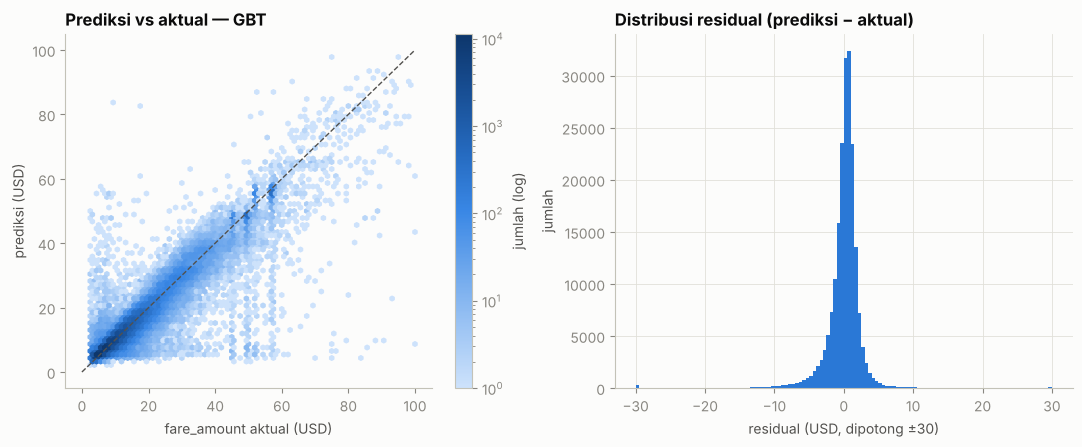

Residual: median = 0.330, |residual| < 2 USD pada 79.0% sampel, < 5 USD pada 95.6%


,n,RMSE,MAE,avg_fare
bucket,,,,
0-2 km,4856813,2.6017,1.1608,6.3591
2-5 km,3898189,2.6063,1.4785,10.6152
5-10 km,1351923,3.8369,2.3618,19.4804
10-20 km,413651,6.4981,4.0698,35.9617
>= 20 km,129476,8.9213,3.6492,52.8699


In [36]:
with timer("analisis galat"):
    pb = pred_best.withColumn("abs_err", F.abs(F.col("prediction") - F.col("fare_amount")))
    pred_sample = pb.sample(fraction=200_000 / n_test, seed=SEED).toPandas()
    err_by_dist = (fitted[best_name].transform(test)
                   .withColumn("bucket", F.when(F.col("distance_km") < 2, "0-2 km")
                                         .when(F.col("distance_km") < 5, "2-5 km")
                                         .when(F.col("distance_km") < 10, "5-10 km")
                                         .when(F.col("distance_km") < 20, "10-20 km")
                                         .otherwise(">= 20 km"))
                   .groupBy("bucket")
                   .agg(F.count("*").alias("n"),
                        F.sqrt(F.avg(F.pow(F.col("prediction") - F.col("fare_amount"), 2))).alias("RMSE"),
                        F.avg(F.abs(F.col("prediction") - F.col("fare_amount"))).alias("MAE"),
                        F.avg("fare_amount").alias("avg_fare"))
                   .toPandas().set_index("bucket")
                   .loc[["0-2 km", "2-5 km", "5-10 km", "10-20 km", ">= 20 km"]])
resid = pred_sample["prediction"] - pred_sample["fare_amount"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
hb = axes[0].hexbin(pred_sample["fare_amount"], pred_sample["prediction"], gridsize=80, bins="log",
                    cmap=SEQ_CMAP, mincnt=1, extent=(0, 100, 0, 100))
axes[0].plot([0, 100], [0, 100], color=INK2, lw=1, ls="--")
axes[0].set_title(f"Prediksi vs aktual — {best_name}")
axes[0].set_xlabel("fare_amount aktual (USD)"); axes[0].set_ylabel("prediksi (USD)"); axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label="jumlah (log)")
axes[1].hist(resid.clip(-30, 30), bins=120, color=PALETTE[0])
axes[1].set_title("Distribusi residual (prediksi − aktual)")
axes[1].set_xlabel("residual (USD, dipotong ±30)"); axes[1].set_ylabel("jumlah")
savefig(fig, "11_prediksi_vs_aktual")
print(f"Residual: median = {resid.median():.3f}, |residual| < 2 USD pada "
      f"{(resid.abs() < 2).mean():.1%} sampel, < 5 USD pada {(resid.abs() < 5).mean():.1%}")
err_by_dist

* Residual terpusat di sekitar nol (median +0,33 USD); 79,0% prediksi meleset < 2 USD dan 95,6% < 5 USD.
* Galat membesar seiring jarak: RMSE 2,6 USD untuk perjalanan < 5 km (82% data uji), 3,8 USD untuk 5–10 km, 6,5 USD untuk 10–20 km, dan 8,9 USD untuk ≥ 20 km. Perjalanan jauh lebih bervariasi karena tol, rute, dan kemacetan yang tidak terlihat dari koordinat.
* Plot prediksi vs aktual memperlihatkan garis-garis vertikal di sekitar 45–58 USD: tarif flat bandara yang nilainya tetap walaupun jaraknya berbeda. Ada pula titik dengan tarif aktual tinggi tetapi prediksi rendah, umumnya perjalanan sangat pendek dengan tarif tidak wajar (kemungkinan salah input atau perjalanan pulang-pergi).

## 6. Hyperparameter Tuning (10 poin)

Model terbaik (GBT) dituning dengan **`CrossValidator` 3-fold** + **`ParamGridBuilder`** dari MLlib.
Parameter yang dicari:

* `maxDepth` — kedalaman tiap pohon (kompleksitas interaksi fitur),
* `maxIter` — jumlah pohon *boosting*,
* `stepSize` — *learning rate*.

Metrik seleksi: RMSE. Tuning dilakukan pada sampel `TUNING_ROWS` dari data **train** saja (data uji tetap
tidak tersentuh).

> **Catatan teknis — `parallelism=1`.** `CrossValidator` di PySpark bisa melatih beberapa model bersamaan
> (`parallelism>1`) memakai *thread pool* Python. Pada percobaan sebelumnya hal ini membuat file *shuffle* dari
> ribuan job GBT tidak pernah dibersihkan (referensinya tertahan di thread JVM yang dipasangkan ke thread
> Python), sehingga direktori sementara Spark membengkak >14 GB dan disk penuh. Dengan `parallelism=1` file
> shuffle lama dibersihkan normal oleh `ContextCleaner` (dibantu `spark.cleaner.periodicGC.interval=1min`).
> Paralelisme tetap terjadi di dalam tiap job (4 core memproses partisi data secara paralel).

In [37]:
gbt = GBTRegressor(featuresCol="features", labelCol="fare_amount", maxBins=64, subsamplingRate=0.8, seed=SEED,
                   checkpointInterval=10)
tune_pipe = Pipeline(stages=[tree_assembler(), gbt])
grid = (ParamGridBuilder()
        .addGrid(gbt.maxDepth, [6, 9])
        .addGrid(gbt.maxIter, [50, 100])
        .addGrid(gbt.stepSize, [0.1, 0.2])
        .build())
cv = CrossValidator(estimator=tune_pipe, estimatorParamMaps=grid,
                    evaluator=RegressionEvaluator(labelCol="fare_amount", metricName="rmse"),
                    numFolds=3, parallelism=1, seed=SEED)

tune_df = (train.sample(fraction=min(1.0, TUNING_ROWS / n_train), seed=SEED + 1).select(MODEL_COLS)
                .repartition(N_PART).persist(StorageLevel.MEMORY_AND_DISK))
print(f"Data tuning: {tune_df.count():,} baris | {len(grid)} kombinasi × 3 fold = {len(grid) * 3} model")
with timer("cross-validation GBT"):
    cv_model = cv.fit(tune_df)

cv_res = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in grid])
cv_res["cv_RMSE"] = cv_model.avgMetrics
cv_res["cv_RMSE_std"] = cv_model.stdMetrics
cv_res = cv_res.sort_values("cv_RMSE").reset_index(drop=True)
best_params = {k: (int(v) if k != "stepSize" else float(v))
               for k, v in cv_res.iloc[0][["maxDepth", "maxIter", "stepSize"]].items()}
print("Hyperparameter terbaik:", best_params)
cv_res

Data tuning: 300,690 baris | 8 kombinasi × 3 fold = 24 model


[waktu] cross-validation GBT: 1,397.0 detik
Hyperparameter terbaik: {'maxDepth': 6, 'maxIter': 100, 'stepSize': 0.1}


,maxDepth,maxIter,stepSize,cv_RMSE,cv_RMSE_std
0,6,100,0.1000,3.2232,0.1297
1,6,50,0.1000,3.2702,0.1293
2,6,50,0.2000,3.2914,0.1280
3,6,100,0.2000,3.2993,0.1232
4,9,50,0.1000,3.4986,0.1005
5,9,100,0.1000,3.5017,0.0990
6,9,50,0.2000,3.6679,0.0638
7,9,100,0.2000,3.7276,0.0634


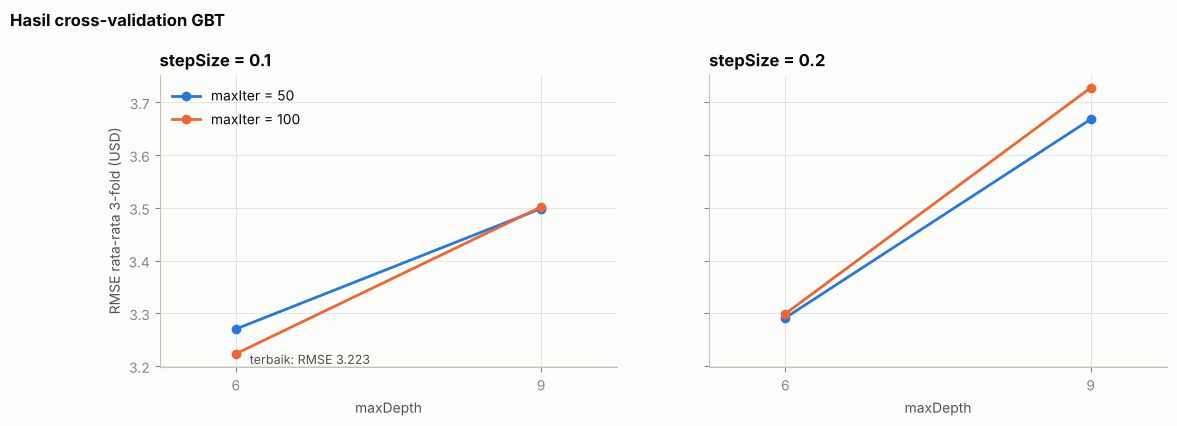

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
best = cv_res.iloc[0]
for ax, step in zip(axes, [0.1, 0.2]):
    sub = cv_res[cv_res["stepSize"] == step]
    for k, it in enumerate([50, 100]):
        s = sub[sub["maxIter"] == it].sort_values("maxDepth")
        ax.plot(s["maxDepth"], s["cv_RMSE"], marker="o", ms=6, color=PALETTE[k], label=f"maxIter = {it}")
    if step == best["stepSize"]:
        ax.annotate(f"terbaik: RMSE {best['cv_RMSE']:.3f}", (best["maxDepth"], best["cv_RMSE"]), xytext=(10, -4),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
    ax.set_title(f"stepSize = {step}"); ax.set_xlabel("maxDepth"); ax.set_xticks([6, 9])
    ax.margins(x=0.25)
axes[0].set_ylabel("RMSE rata-rata 3-fold (USD)")
axes[0].legend(loc="upper left")
fig.suptitle("Hasil cross-validation GBT", x=0.01, y=1.05, ha="left", fontweight="bold")
savefig(fig, "12_cv_tuning")

**Hasil cross-validation (300.690 baris, 24 model, ±23 menit):**

* Konfigurasi terbaik: `maxDepth=6, maxIter=100, stepSize=0.1` dengan RMSE CV 3,223 ± 0,130 USD.
* **Pohon yang lebih dalam (`maxDepth=9`) justru lebih buruk** (RMSE 3,50–3,73). Dengan hanya ±200 ribu baris latih per fold, pohon sedalam 9 level (hingga 512 daun) mulai menghafal noise. Kombinasi pohon dalam dan *learning rate* besar (0,2) adalah yang paling *overfit*.
* Untuk `maxDepth=6`, menambah pohon dari 50 ke 100 membantu bila `stepSize=0.1` (3,270 → 3,223), tetapi tidak bila `stepSize=0.2` (3,291 → 3,299): dengan *learning rate* besar model sudah konvergen lebih cepat, sehingga pohon tambahan mulai *overfit*.

### 6.1 Melatih ulang model final dengan hyperparameter terbaik
Konfigurasi terbaik dilatih ulang pada sampel train yang jauh lebih besar (`FINAL_TRAIN_ROWS`), lalu
dibandingkan dengan GBT awal (Bagian 4) pada data uji yang sama. Agar efek tuning dan efek penambahan data
terlihat terpisah, konfigurasi terbaik juga dilatih pada sampel 2 juta baris yang sama dengan Bagian 4.

In [39]:
final_frac = min(1.0, FINAL_TRAIN_ROWS / n_train)
final_train = train.sample(fraction=final_frac, seed=SEED + 2).select(MODEL_COLS)
final_pipe = Pipeline(stages=[tree_assembler(),
    GBTRegressor(featuresCol="features", labelCol="fare_amount", maxBins=64, subsamplingRate=0.8, seed=SEED,
                 checkpointInterval=10, **best_params)])
with timer("latih GBT final"):
    final_model = final_pipe.fit(final_train)
with timer("evaluasi GBT final"):
    final_test = regression_metrics(final_model.transform(test))
n_final_train = int(round(final_frac * n_train))

# Pengaruh tuning saja (data latih sama = sampel perbandingan model)
with timer("latih GBT tuned (sampel perbandingan)"):
    tuned_same = Pipeline(stages=[tree_assembler(),
        GBTRegressor(featuresCol="features", labelCol="fare_amount", maxBins=64, subsamplingRate=0.8,
                     seed=SEED, **best_params)]).fit(train_s)
tuned_same_test = regression_metrics(tuned_same.transform(test))

compare = pd.DataFrame([
    {"model": f"GBT awal (maxDepth=6, maxIter=60, stepSize=0.1), {n_train_s/1e6:.1f} jt baris",
     **{k: results.loc['GBT', f'test_{k}'] for k in ('RMSE', 'MAE', 'R2')}},
    {"model": f"GBT tuned, {n_train_s/1e6:.1f} jt baris", **{k: tuned_same_test[k] for k in ('RMSE', 'MAE', 'R2')}},
    {"model": f"GBT tuned, ~{n_final_train/1e6:.1f} jt baris (model final)",
     **{k: final_test[k] for k in ('RMSE', 'MAE', 'R2')}},
]).set_index("model")
compare["perbaikan_RMSE_vs_awal"] = 1 - compare["RMSE"] / compare["RMSE"].iloc[0]
compare

[waktu] latih GBT final: 645.4 detik


[waktu] evaluasi GBT final: 34.0 detik


[waktu] latih GBT tuned (sampel perbandingan): 174.6 detik


,RMSE,MAE,R2,perbaikan_RMSE_vs_awal
model,,,,
"GBT awal (maxDepth=6, maxIter=60, stepSize=0.1), 2.0 jt baris",3.1701,1.5728,0.8865,0.0000
"GBT tuned, 2.0 jt baris",3.1103,1.5249,0.8908,0.0189
"GBT tuned, ~8.0 jt baris (model final)",3.0880,1.5164,0.8923,0.0259


**Dampak tuning pada data uji (10,65 juta baris):**

* Dengan data latih yang sama (±2 juta baris), hyperparameter hasil tuning menurunkan RMSE dari 3,170 menjadi 3,110 USD (−1,9%) dan menaikkan R² dari 0,887 ke 0,891.
* Melatih ulang konfigurasi terbaik dengan ±8 juta baris menurunkan RMSE lagi menjadi **3,088 USD** (total −2,6% dibanding GBT awal), dengan MAE 1,516 USD dan R² **0,892**. Tambahan data dari 2 juta ke 8 juta baris memberi perbaikan yang lebih kecil (−0,7%) daripada efek tuning: kurva belajar mulai landai, sehingga keterbatasan model kini lebih terletak pada fitur (jarak tempuh riil, kondisi lalu lintas) daripada jumlah data.
* Model final disimpan di `models/gbt_tuned_final` dan dapat dimuat ulang dengan `PipelineModel.load(...)`.

In [40]:
final_model.write().overwrite().save(f"{MODEL_DIR}/gbt_tuned_final")
imp_final = pd.Series(final_model.stages[-1].featureImportances.toArray(), index=TREE_FEATURES)
imp_final.sort_values(ascending=False).head(10).to_frame("importance (model final)")

,importance (model final)
distance_km,0.6025
bearing,0.0465
dropoff_latitude,0.0410
dropoff_dist_jfk,0.0301
after_fare_hike,0.0214
hour,0.0210
dropoff_dist_center,0.0210
year_frac,0.0208
manhattan_km,0.0185
pickup_dist_jfk,0.0184


### 6.2 Contoh penggunaan model final
Prediksi untuk beberapa perjalanan hipotetis (pipeline `add_features` → model), misalnya perjalanan
Midtown → JFK pada jam sibuk vs perjalanan pendek di Manhattan pada malam hari.

In [41]:
examples = spark.createDataFrame([
    (None, "2015-06-10 17:30:00", -73.9855, 40.7580, -73.7781, 40.6413, 1, "Times Square → JFK, Rabu 17.30"),
    (None, "2015-06-13 23:10:00", -73.9855, 40.7580, -73.9772, 40.7527, 2, "Times Square → Grand Central, Sabtu 23.10"),
    (None, "2011-06-10 17:30:00", -73.9855, 40.7580, -73.7781, 40.6413, 1, "Times Square → JFK, 2011 (sebelum kenaikan tarif)"),
    (None, "2015-06-10 09:00:00", -73.8740, 40.7769, -73.9855, 40.7580, 1, "LaGuardia → Times Square, Rabu 09.00"),
], "fare_amount double, pickup_datetime string, pickup_longitude double, pickup_latitude double, "
   "dropoff_longitude double, dropoff_latitude double, passenger_count int, keterangan string")
examples = examples.withColumn("pickup_datetime", F.to_timestamp("pickup_datetime"))
(final_model.transform(add_features(examples))
    .select("keterangan", F.round("distance_km", 2).alias("jarak_km"), F.round("prediction", 2).alias("prediksi_USD"))
    .show(truncate=False))

+-------------------------------------------------+--------+------------+
|keterangan                                       |jarak_km|prediksi_USD|
+-------------------------------------------------+--------+------------+
|Times Square → JFK, Rabu 17.30                   |21.77   |57.68       |
|Times Square → Grand Central, Sabtu 23.10        |0.91    |6.21        |
|Times Square → JFK, 2011 (sebelum kenaikan tarif)|21.77   |49.37       |
|LaGuardia → Times Square, Rabu 09.00             |9.62    |44.35       |
+-------------------------------------------------+--------+------------+



## 7. Kesimpulan

1. **Data besar diolah sepenuhnya dengan Spark.** 55,4 juta baris dimuat, diaudit, dibersihkan (tersisa 53,2 juta baris / 96,1%), dan diubah menjadi 28 fitur tanpa pernah memindahkan data mentah ke Pandas. ETL, EDA, dan preprocessing selesai dalam ±7 menit pada satu mesin 4 core; seluruh notebook ±53 menit.
2. **EDA** menemukan ±4% data kotor (koordinat 0/di luar kota, tarif negatif, penumpang 0), label zona waktu yang menyesatkan, perubahan tarif resmi 4 September 2012, serta pentingnya bandara (tarif flat).
3. **Jarak** adalah prediktor utama, tetapi waktu (tahun/kenaikan tarif, jam) dan lokasi (jarak ke bandara dan pusat kota) menambah akurasi yang berarti.
4. Dari empat algoritma MLlib, **Gradient-Boosted Trees** paling akurat. Setelah tuning dengan `CrossValidator` dan pelatihan ulang dengan ±8 juta baris, model final mencapai **RMSE 3,09 USD, MAE 1,52 USD, R² 0,892** pada 10,65 juta baris data uji, jauh lebih baik daripada baseline (RMSE 9,41 USD).
5. Prediksi model masuk akal: Times Square → JFK pada Rabu 17.30 tahun 2015 diprediksi 57,68 USD, mendekati tarif flat JFK 52 USD + surcharge jam sibuk 4,50 USD. Perjalanan yang sama pada 2011 diprediksi 49,37 USD, ±8 USD lebih murah; model menangkap kenaikan tarif flat 2012 (45 → 52 USD).

**Saran pengembangan:** gunakan jarak rute jalan sebenarnya (mis. OSRM) alih-alih jarak garis lurus, tambahkan data cuaca/lalu lintas, latih pada 100% data di klaster Spark, dan perluas grid tuning (`minInstancesPerNode`, `subsamplingRate`) pada sampel yang lebih besar.

Laporan lengkap: `laporan/Laporan_Tugas_PySpark.md` (juga tersedia `.docx` dan `.pdf`).

In [42]:
summary = {
    "spark_version": pyspark.__version__,
    "n_raw": n_raw, "n_clean": n_clean, "n_train": n_train, "n_test": n_test,
    "n_model_train_sample": n_train_s, "n_tuning": TUNING_ROWS, "n_final_train": n_final_train,
    "cleaning_funnel": funnel["baris_dibuang"].astype(int).to_dict(),
    "anomalies": anomaly_pd["jumlah_baris"].astype(int).to_dict(),
    "fare_quantiles": dict(zip(["p01", "p05", "p25", "p50", "p75", "p95", "p99"], fare_q)),
    "model_results": results.reset_index().to_dict(orient="records"),
    "best_model_before_tuning": best_name,
    "cv_results": cv_res.to_dict(orient="records"),
    "best_params": best_params,
    "tuning_comparison": compare.reset_index().to_dict(orient="records"),
    "final_test_metrics": final_test,
    "error_by_distance": err_by_dist.reset_index().to_dict(orient="records"),
    "airport_trips": airport_pd.to_dict(orient="records"),
    "feature_importance_final": imp_final.sort_values(ascending=False).to_dict(),
    "timings_seconds": TIMINGS,
}
with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
results.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"))
cv_res.to_csv(os.path.join(RESULTS_DIR, "cv_results.csv"), index=False)
pd.Series(TIMINGS, name="detik").to_frame()

,detik
load_raw + count,6.3000
tulis prepared.parquet,51.7000
summary statistik,50.9000
audit anomali,4.1000
distribusi fare,13.6000
agregasi temporal,47.2000
agregasi jarak,22.3000
peta kepadatan,10.3000
agregasi bandara,18.0000
funnel pembersihan,4.5000


In [43]:
train_s.unpersist(); tune_df.unpersist()
spark.stop()